In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")

pd.set_option('display.float_format', '{:.2f}'.format)

## 1. Data Prep

#### 1.1 Read data files
To read data files in CSV format, we use the `read_csv()` function from the pandas library. This function allows us to load the data into a DataFrame
The `read_csv()` function takes the file path of the CSV file as an argument and returns a DataFrame containing the data.

In [2]:
# Read Passenger data 'International_Report_Passengers.csv'
pax = pd.read_csv('International_Report_Passengers.csv')

# Lets sort the and rename few columns for better understanding
pax = pax.sort_values(by=['usg_apt', 'Year', 'Month', 'carrier'], ascending=[True, True, True, True]).reset_index(drop= True)
pax = pax.rename(columns={'usg_apt': 'AirportCode', 'carrier': 'Airline', 'type': 'Type'})
pax.head()

,data_dte,Year,Month,usg_apt_id,AirportCode,usg_wac,fg_apt_id,fg_apt,fg_wac,airlineid,Airline,carriergroup,Type,Scheduled,Charter,Total
0,07/01/2015,2015,7,NaN,1B1,NaN,16271.00,YYZ,936.00,21437,13Q,0,Passengers,0,10,10
1,12/01/2015,2015,12,NaN,1B1,22.00,16271.00,YYZ,936.00,21437,13Q,0,Passengers,0,3,3
2,02/01/2020,2020,2,NaN,3TX,NaN,16217.00,YUL,941.00,21437,13Q,0,Passengers,0,4,4
3,08/01/2022,2022,8,NaN,A38,1.00,16604.00,BC5,906.00,20272,KAH,1,Passengers,7,0,7
4,07/01/2023,2023,7,10051.00,A38,1.00,16036.00,YDS,NaN,20272,KAH,1,Passengers,3,0,3


In [11]:
# read freight data
freight = pd.read_csv('International_Report_Freight.csv')
freight = freight.sort_values(by=['usg_apt', 'Year', 'Month', 'carrier'], ascending=[True, True, True, True]).reset_index(drop= True)
freight = freight.rename(columns={'usg_apt': 'AirportCode', 'carrier': 'Airline', 'type': 'Type'})
freight.head()


,data_dte,Year,Month,usg_apt_id,AirportCode,usg_wac,fg_apt_id,fg_apt,fg_wac,airlineid,Airline,carriergroup,Type,Scheduled,Charter,Total
0,06.01.20,2020,6,NaN,1FL,NaN,15256.00,TLS,NaN,20110,ADB,0,Freight,0,40,40
1,12.01.20,2020,12,NaN,1FL,33.00,16178.00,YQX,961.00,20110,ADB,0,Freight,0,50,50
2,03.01.24,2024,3,NaN,1FL,NaN,12064.00,HAJ,429.00,20405,N8,1,Freight,0,17,17
3,03.01.21,2021,3,NaN,A02,1.00,13518.00,MUC,429.00,20405,N8,1,Freight,0,109,109
4,01.01.01,2001,1,NaN,A31,1.00,12143.00,HKG,729.00,19917,5X,1,Freight,"1,473",0,"1,473"


Combine Datasets using `pd.concat`
- `pd.concat` function is used to concatenate pandas objects along a particular axis (rows or columns).
It is useful for combining datasets, appending rows, or adding columns.

In [18]:
# Combine Passenger and Freight Data into one DataFrame
df = pd.concat([pax, freight], axis=0)

In [20]:
# General Information on the combined data 
print("Data from Year :", df["Year"].min(), "to", df["Year"].max())
print("Shape of the data: ", df.shape)
print("Number of rows: ", df.shape[0])
print("Number of columns: ", df.shape[1])
print("Number of Airports: ", df["AirportCode"].nunique())
print("Number of Airlines: ", df["Airline"].nunique())
print("Number of Types: ", df["Type"].nunique())

Data from Year : 1990 to 2024
Shape of the data:  (1432379, 16)
Number of rows:  1432379
Number of columns:  16
Number of Airports:  1032
Number of Airlines:  774
Number of Types:  2


#### 1.2 Data Understanding & cleaning

##### 1.2.1 Select us look at the data and select relevant data 

Here is an overview of all the columns in the dataset.

| Column Name    | Description                                                                                      | Data Type        |
|----------------|--------------------------------------------------------------------------------------------------|------------------|
| **data_dte**   | Date of data collection                                                                                            | Timestamp |
| **Year**       | Year                                                                                            | Number           |
| **Month**      | Month                                                                                           | Number           |
| **usg_apt_id** | US Gateway Airport ID - assigned by US DOT to identify an airport                                | Number           |
| **AirportCode** | Airport code                                | Text           |
| **usg_wac**    | US Gateway World Area Code - assigned by US DOT to represent a geographic territory              | Number           |
| **fg_apt_id**  | Foreign Gateway Airport ID - assigned by US DOT to identify an airport                          | Number           |
| **fg_apt**     | Foreign Gateway Airport Code - usually assigned by IATA, but in absence of IATA designation, may show FAA-assigned code | Text             |
| **fg_wac**     | Foreign Gateway World Area Code - assigned by US DOT to represent a geographic territory        | Number           |
| **airlineid**  | Airline ID - assigned by US DOT to identify an air carrier                                       | Number           |
| **Airline**    | IATA-assigned air carrier code. If carrier has no IATA code, ICAO- or FAA-assigned code may be used | Text             |
| **carriergroup** | Carrier Group Code - 1 denotes US domestic air carriers, 0 denotes foreign air carriers         | Number           |
| **Type**       | Defines the type of the two metrics in this table, can be Freight or Passengers                 | Text             |
| **Scheduled**  | Metric flown by scheduled service operations                                                    | Number           |
| **Charter**    | Metric flown by charter operations                                                             | Number           |
| **Total**   | Refers to the total  number of passengers flown (when "Type" is Passengers) or total kilograms of Cargo flown (when "Type" is Cargo)                             | Number           |


##### 1.2.2 Extract only those airports which are available in year 2024

In [32]:
# Select only those airport for which data is available for year 2024.

airports = df['AirportCode'][df['Year'] == 2024].unique()
#print(airports)
new_df = df[df['AirportCode'].isin(airports)].reset_index(drop=True)
new_df.head()

,data_dte,Year,Month,usg_apt_id,AirportCode,usg_wac,fg_apt_id,fg_apt,fg_wac,airlineid,Airline,carriergroup,Type,Scheduled,Charter,Total
0,04/01/1990,1990,4,NaN,ABE,NaN,NaN,FPO,NaN,19952,KW,1,Passengers,0,30,30
1,05/01/1990,1990,5,NaN,ABE,NaN,11731.00,FPO,NaN,19952,KW,1,Passengers,0,30,30
2,07/01/1990,1990,7,NaN,ABE,NaN,13180.00,MBJ,NaN,19704,CO,1,Passengers,143,0,143
3,11/01/1990,1990,11,NaN,ABE,NaN,11731.00,FPO,204.00,19952,KW,1,Passengers,0,138,138
4,10/01/1992,1992,10,10135.00,ABE,NaN,16217.00,YUL,941.00,20355,US,1,Passengers,100,0,100


In [33]:
# Let's check the change in data size
print("Data from Year :", new_df["Year"].min(), "to", new_df["Year"].max())
print("Shape of the data: ", new_df.shape)
print("Number of rows: ", new_df.shape[0])
print("Number of columns: ", new_df.shape[1])
print("Number of Airports: ", new_df["AirportCode"].nunique())
print("Number of Airlines: ", new_df["Airline"].nunique())
print("Number of Types: ", new_df["Type"].nunique())

Data from Year : 1990 to 2024
Shape of the data:  (1421266, 16)
Number of rows:  1421266
Number of columns:  16
Number of Airports:  321
Number of Airlines:  761
Number of Types:  2


In [35]:
# Let's look at the first few rows of the combined data
print("\nFirst 5 Rows:")
print(new_df.head(5))


First 5 Rows:
     data_dte  Year  Month  usg_apt_id AirportCode  usg_wac  fg_apt_id fg_apt  \
0  04/01/1990  1990      4         NaN         ABE      NaN        NaN    FPO   
1  05/01/1990  1990      5         NaN         ABE      NaN   11731.00    FPO   
2  07/01/1990  1990      7         NaN         ABE      NaN   13180.00    MBJ   
3  11/01/1990  1990     11         NaN         ABE      NaN   11731.00    FPO   
4  10/01/1992  1992     10    10135.00         ABE      NaN   16217.00    YUL   

   fg_wac  airlineid Airline  carriergroup        Type Scheduled Charter Total  
0     NaN      19952      KW             1  Passengers         0      30    30  
1     NaN      19952      KW             1  Passengers         0      30    30  
2     NaN      19704      CO             1  Passengers       143       0   143  
3  204.00      19952      KW             1  Passengers         0     138   138  
4  941.00      20355      US             1  Passengers       100       0   100  


##### 1.2.3 Lets look at the data



The `sns.heatmap` function in the Seaborn library is used to create heatmaps, which are graphical representations of data where individual values are represented by colors. This function is particularly useful for visualizing matrices, such as correlation matrices, to identify patterns, relationships, and outliers in the data.

- **data**: The data to be plotted, typically a 2D dataset like a DataFrame or a 2D array.
- **cmap**: The colormap to use for the heatmap. Common options include 'viridis', 'coolwarm', and 'magma'.
- **cbar**: If `True`, includes a color bar to the right of the heatmap.
- **xticklabels** and **yticklabels**: Labels for the x and y axes, respectively. Can be set to `True`, `False`, or a list of labels.


<Axes: >

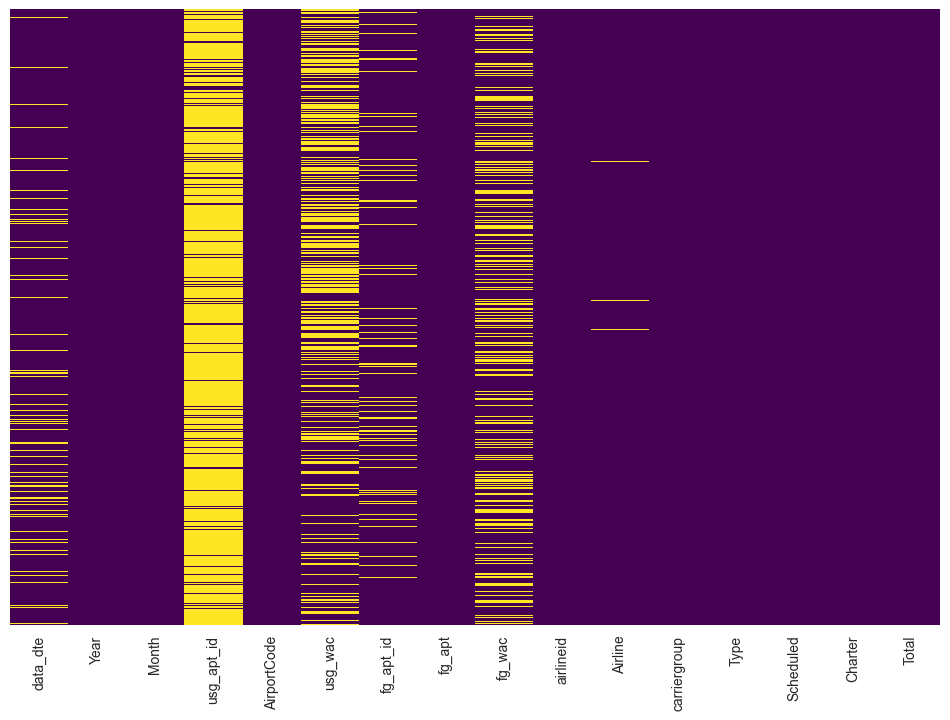

In [36]:
# Set the figure size
plt.figure(figsize=(12, 8))
# Create a heatmap to visualize missing values
sns.heatmap(new_df.isnull(), cbar=False, cmap='viridis', yticklabels=False)

In [40]:
# Drop the columns that are not required ['data_dte','Month', 'usg_apt_id', 'usg_wac', 'fg_apt_id', 'fg_apt', 'fg_wac']
new_df = new_df.drop(['data_dte','Month', 'usg_apt_id', 'usg_wac', 'fg_apt_id', 'fg_apt', 'fg_wac'], axis=1)
new_df.head()

,Year,AirportCode,airlineid,Airline,carriergroup,Type,Scheduled,Charter,Total
0,1990,ABE,19952,KW,1,Passengers,0,30,30
1,1990,ABE,19952,KW,1,Passengers,0,30,30
2,1990,ABE,19704,CO,1,Passengers,143,0,143
3,1990,ABE,19952,KW,1,Passengers,0,138,138
4,1992,ABE,20355,US,1,Passengers,100,0,100


##### 1.2.4 Handling Missing values

In [41]:
# Lets check how the data looks like now
print("Dataset Info:")
print(new_df.info())

## Question: Do you see any anomalies ??

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1421266 entries, 0 to 1421265
Data columns (total 9 columns):
 #   Column        Non-Null Count    Dtype 
---  ------        --------------    ----- 
 0   Year          1421266 non-null  int64 
 1   AirportCode   1421266 non-null  object
 2   airlineid     1421266 non-null  int64 
 3   Airline       1418348 non-null  object
 4   carriergroup  1421266 non-null  int64 
 5   Type          1421266 non-null  object
 6   Scheduled     1421266 non-null  object
 7   Charter       1421266 non-null  object
 8   Total         1421266 non-null  object
dtypes: int64(3), object(6)
memory usage: 97.6+ MB
None


Quite a few columns with significant missing values.

- From the column description, we see that there are many columns which are not relevant and can be removed. 
- E.g., data_dte, Month, usg_apt_id, usg_wac,fg_apt_id, fg_apt, fg_wac, airline_id.
- These are also those columns which have the most missing values --> so lets remove the noisy irrelevant data

In [42]:
# Check for missing values --> in a straightforward way
print("\nMissing Values:")
print(new_df.isnull().sum())
new_df.isnull().head()


Missing Values:
Year               0
AirportCode        0
airlineid          0
Airline         2918
carriergroup       0
Type               0
Scheduled          0
Charter            0
Total              0
dtype: int64


,Year,AirportCode,airlineid,Airline,carriergroup,Type,Scheduled,Charter,Total
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False


<Axes: >

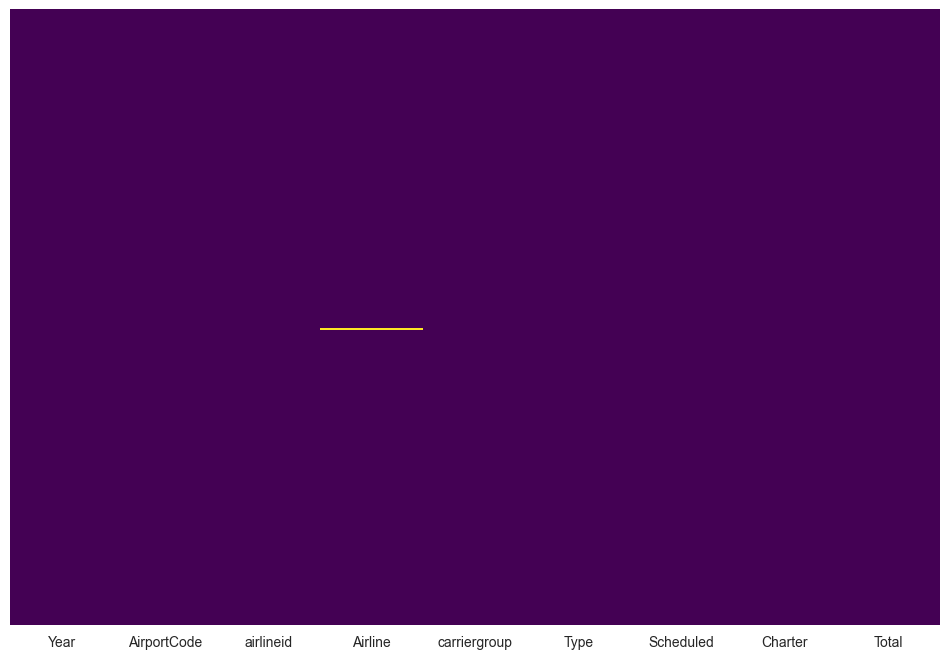

In [43]:
# Lets try to visualize the remaining data 
# Set the figure size
plt.figure(figsize=(12, 8))
# Create a heatmap to visualize missing values
sns.heatmap(new_df.isnull(), cbar=False, cmap='viridis', yticklabels=False)


And now, only one column of relevance has some missing values. Let us see how we can fix it.

In [44]:
# Look at the misig values in the data
missing_data = new_df[(new_df.Airline.isnull())]
missing_data.head()

,Year,AirportCode,airlineid,Airline,carriergroup,Type,Scheduled,Charter,Total
843,2006,ACT,20415,NaN,1,Passengers,0,51,51
1268,2000,ACY,20415,NaN,1,Passengers,0,211,211
1270,2000,ACY,20415,NaN,1,Passengers,0,211,211
1287,2005,ACY,20415,NaN,1,Passengers,165,0,165
1308,2007,ACY,20415,NaN,1,Passengers,174,0,174


In [45]:
#get the unique airlineids for which airline information is missing by using unique() function
missing_airlineids = missing_data.airlineid.unique()
print("Missing Airline IDs: ", missing_airlineids)

Missing Airline IDs:  [20415 20414]


In [46]:
# Check the non-missing entries to see the corresponding Airline values 

non_missing_data = new_df[~(new_df.Airline.isnull())]
print("Non missing rows: ",non_missing_data.shape)

sub_df = non_missing_data[(non_missing_data.airlineid.isin(missing_airlineids))]
#sub_df[['airlineid', 'Airline']]

## Get unique combinations 
#sub_df[['airlineid', 'Airline']].value_counts() # or 
sub_df[['airlineid', 'Airline']].drop_duplicates()


Non missing rows:  (1418348, 9)


,airlineid,Airline
1280,20415,XG
199562,20414,OW


Lets correct the missing values by filling them 

In [ ]:
# correct the missing values 
new_df.loc[new_df.airlineid == 20415 , 'Airline'] = 'XG'
new_df.loc[new_df.airlineid == 20414 , 'Airline'] = 'OW'

In [48]:
# recheck if any missing values are left
print(new_df.isnull().sum())

Year            0
AirportCode     0
airlineid       0
Airline         0
carriergroup    0
Type            0
Scheduled       0
Charter         0
Total           0
dtype: int64


<Axes: >

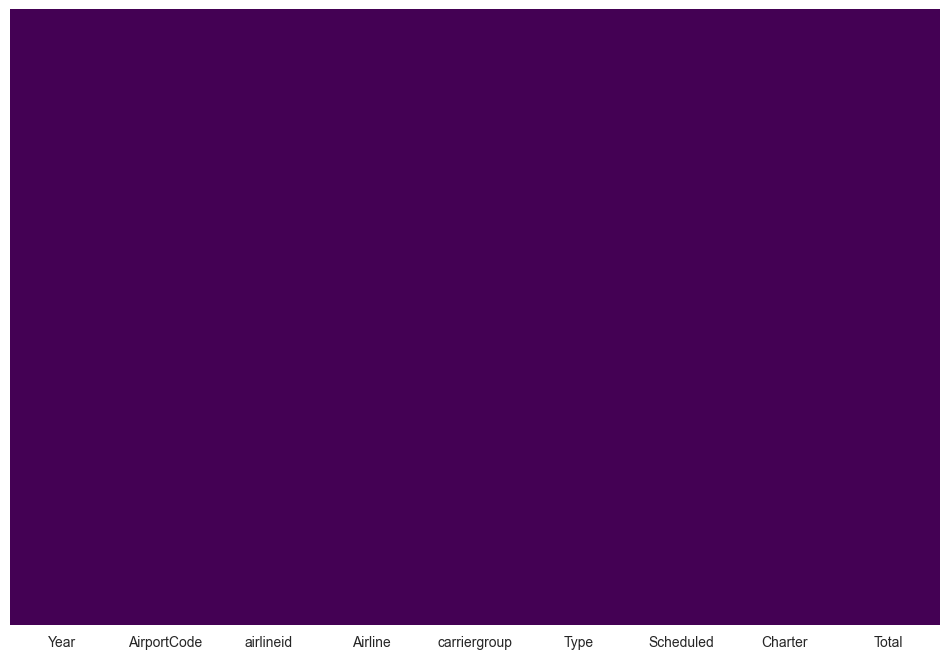

In [49]:
# We can also visualize to validate
# Set the figure size
plt.figure(figsize=(12, 8))
# Create a heatmap to visualize missing values after the fix
sns.heatmap(new_df.isnull(), cbar=False, cmap='viridis', yticklabels=False)

##### 1.2.5 Check Data Types

In [50]:
# get the datatype of each column using dtypes 
new_df.dtypes

Year             int64
AirportCode     object
airlineid        int64
Airline         object
carriergroup     int64
Type            object
Scheduled       object
Charter         object
Total           object
dtype: object

Note, some of the columns are set to the wrong data type. We need to fix that one by one

In [51]:
# Check and replace commas in the 'Scheduled' column
new_df['Scheduled'] = new_df['Scheduled'].astype(str)
new_df['Scheduled'] = new_df['Scheduled'].str.replace(',', '')
new_df['Scheduled'] = new_df['Scheduled'].astype('int64')
new_df.dtypes

Year             int64
AirportCode     object
airlineid        int64
Airline         object
carriergroup     int64
Type            object
Scheduled        int64
Charter         object
Total           object
dtype: object

In [52]:
# Check and replace commas in the 'Charter' column
new_df['Charter'] = new_df['Charter'].astype(str)
new_df['Charter'] = new_df['Charter'].str.replace(',', '')
new_df['Charter'] = new_df['Charter'].astype('int64')
new_df.dtypes

Year             int64
AirportCode     object
airlineid        int64
Airline         object
carriergroup     int64
Type            object
Scheduled        int64
Charter          int64
Total           object
dtype: object

In [54]:
# Check and replace commas in the 'Totals' column
new_df['Total'] = new_df['Total'].astype(str)
new_df['Total'] = new_df['Total'].str.replace(',', '')
new_df['Total'] = new_df['Total'].astype('int64')
new_df.dtypes

Year             int64
AirportCode     object
airlineid        int64
Airline         object
carriergroup     int64
Type            object
Scheduled        int64
Charter          int64
Total            int64
dtype: object

##### 1.2.6 Saving clean data as file

In [55]:
# Save the cleaned data to a new csv file using to_csv()
new_df.to_csv('International_Report_cleaned.csv', index=False)

In [56]:
# Read the cleaned data
cleaned_df = pd.read_csv('International_Report_cleaned.csv')
print('Data shape: ', cleaned_df.shape)
cleaned_df.head()

Data shape:  (1421266, 9)


,Year,AirportCode,airlineid,Airline,carriergroup,Type,Scheduled,Charter,Total
0,1990,ABE,19952,KW,1,Passengers,0,30,30
1,1990,ABE,19952,KW,1,Passengers,0,30,30
2,1990,ABE,19704,CO,1,Passengers,143,0,143
3,1990,ABE,19952,KW,1,Passengers,0,138,138
4,1992,ABE,20355,US,1,Passengers,100,0,100


In [58]:
# General summary of the clean data
print('unique Type: ', cleaned_df['Type'].unique())
print('unique carrier groups: ', cleaned_df['carriergroup'].unique())
print('Total unique Airline: ', len(cleaned_df['Airline'].unique()))
print('Total unique AirportCode: ', len(cleaned_df['AirportCode'].unique()))
cleaned_df.dtypes

unique Type:  ['Passengers' 'Freight']
unique carrier groups:  [1 0]
Total unique Airline:  761
Total unique AirportCode:  321


Year             int64
AirportCode     object
airlineid        int64
Airline         object
carriergroup     int64
Type            object
Scheduled        int64
Charter          int64
Total            int64
dtype: object

In [59]:
#Statistics of the cleaned data using describe()
cleaned_df.describe()

,Year,airlineid,carriergroup,Scheduled,Charter,Total
count,1421266.00,1421266.00,1421266.00,1421266.00,1421266.00,1421266.00
mean,2007.86,20020.72,0.55,3736.94,127.74,3864.77
std,9.80,519.76,0.50,7125.04,727.36,7101.30
min,1990.00,19386.00,0.00,0.00,0.00,1.00
25%,2000.00,19576.00,0.00,7.00,0.00,84.00
50%,2008.00,19917.00,1.00,389.00,0.00,596.00
75%,2016.00,20229.00,1.00,4678.75,0.00,4854.00
max,2024.00,22130.00,1.00,149898.00,58284.00,150195.00


## 2. Exploration and Visualization

#### 2.1 Airport operations over the year

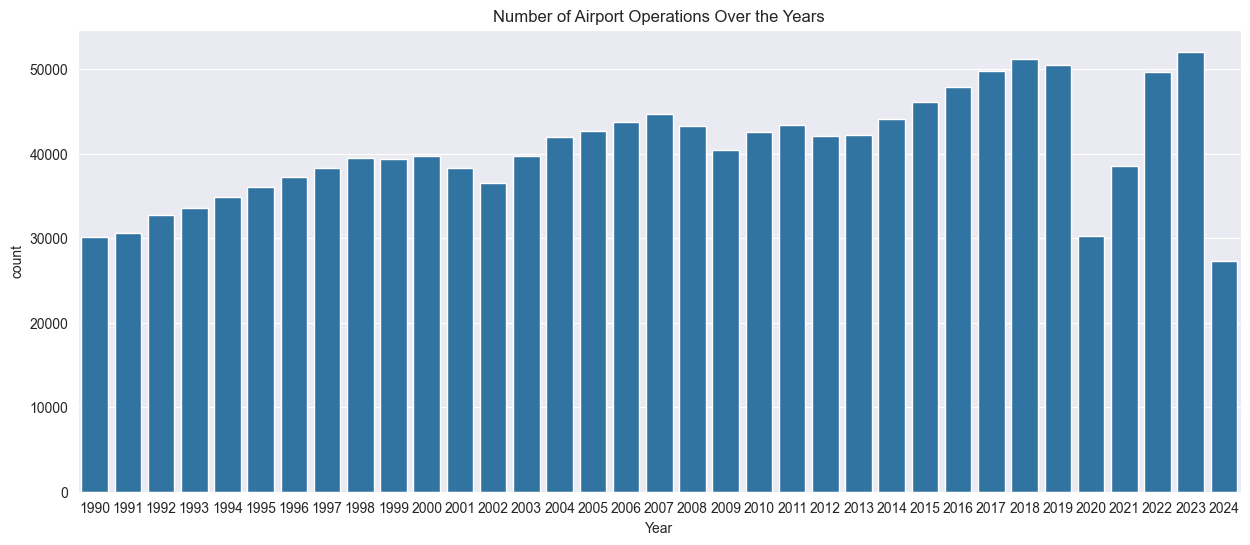

In [60]:
# Number of airport operations over the years
plt.figure(figsize=(15, 6))
sns.countplot(x='Year', data=cleaned_df)
plt.title('Number of Airport Operations Over the Years')
plt.show()

#### 2.2 Unique airports over the years

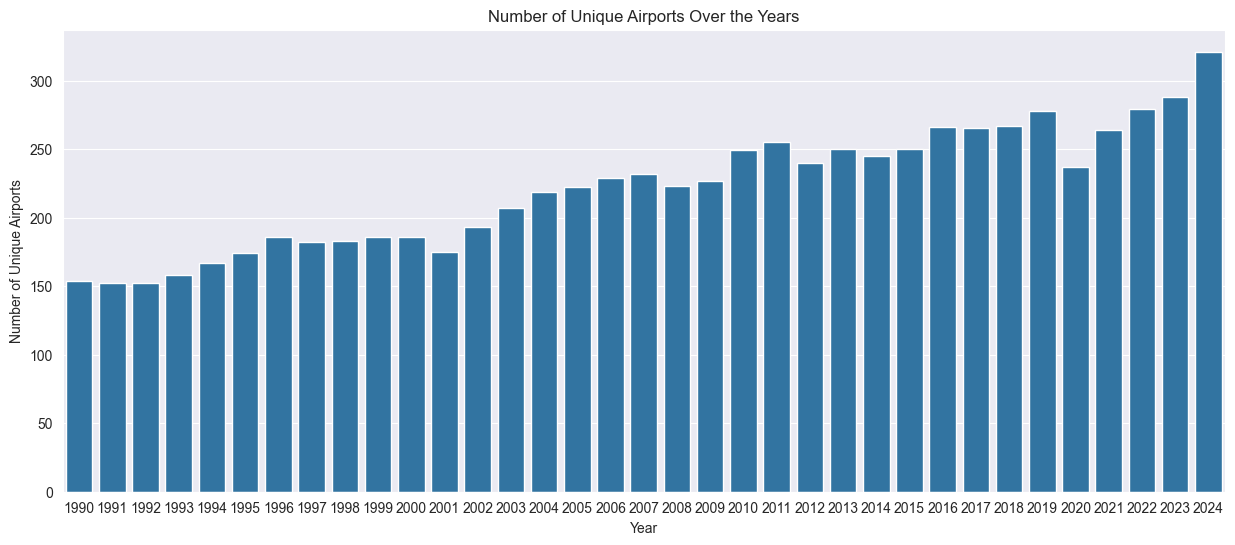

In [61]:
# Visualize number of unique airports over the years
unique_airports_per_year = cleaned_df.groupby('Year')['AirportCode'].nunique().reset_index()

plt.figure(figsize=(15, 6))
sns.barplot(data=unique_airports_per_year, x='Year', y='AirportCode')
plt.title('Number of Unique Airports Over the Years')
plt.xlabel('Year')
plt.ylabel('Number of Unique Airports')
plt.show()

#### 2.3 Freight and Passenger distribution over the years

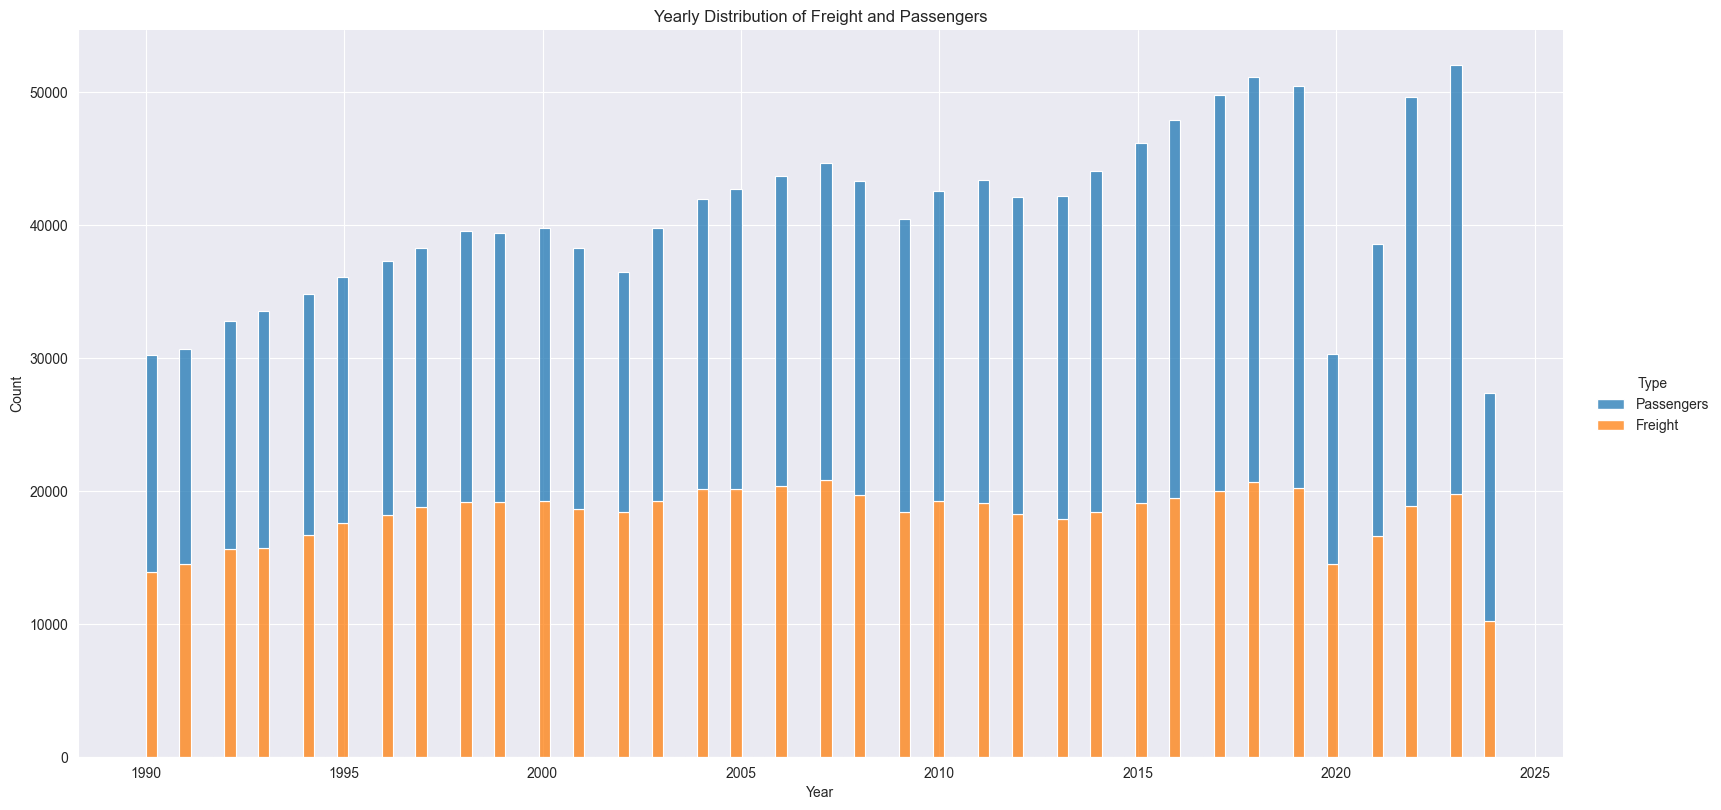

In [62]:
# Passenger and freight distribution over the years 
sns.displot(data=cleaned_df, x="Year", hue="Type", multiple="stack", height=8, aspect=2)
plt.title('Yearly Distribution of Freight and Passengers')
plt.xlabel('Year')
plt.ylabel('Count')
plt.show()

#### 2.4 Air traffic type distribution over the years

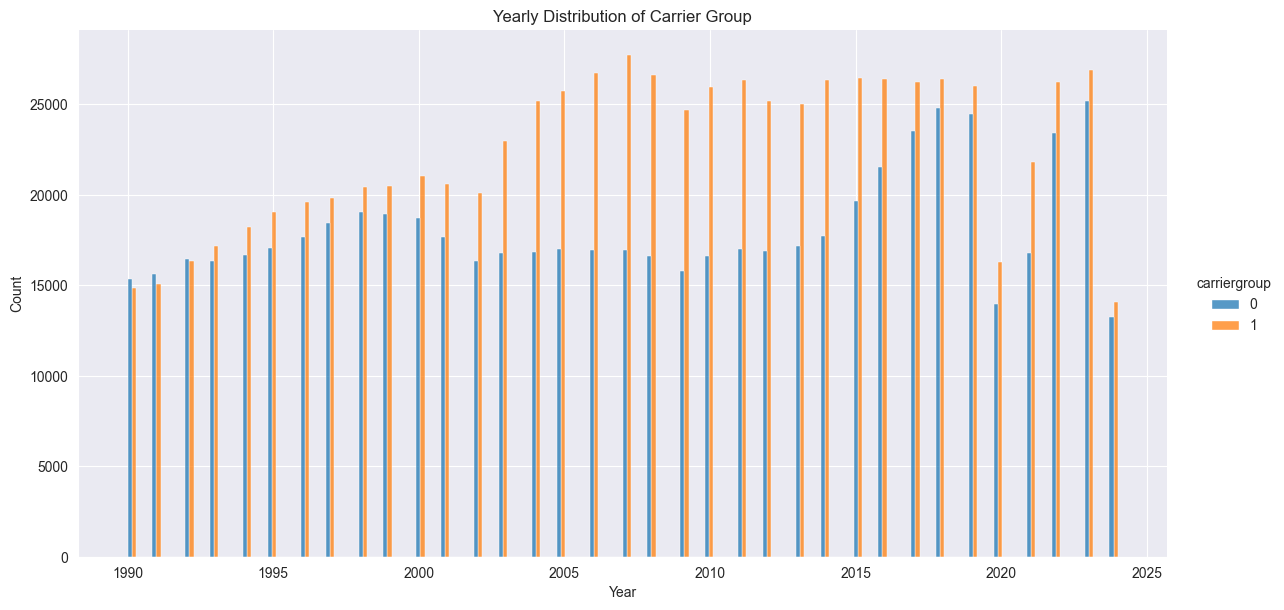

In [63]:
# Aircraft distribution over the years
sns.displot(data=cleaned_df, x="Year", hue="carriergroup", multiple="dodge",  height=6, aspect=2)
plt.title('Yearly Distribution of Carrier Group')
plt.xlabel('Year')
plt.ylabel('Count')
plt.show()

# Carrier Group Code - 1 denotes US domestic air services, 0 denotes international air services  

#### 2.5 Passenger and Freight Distribution

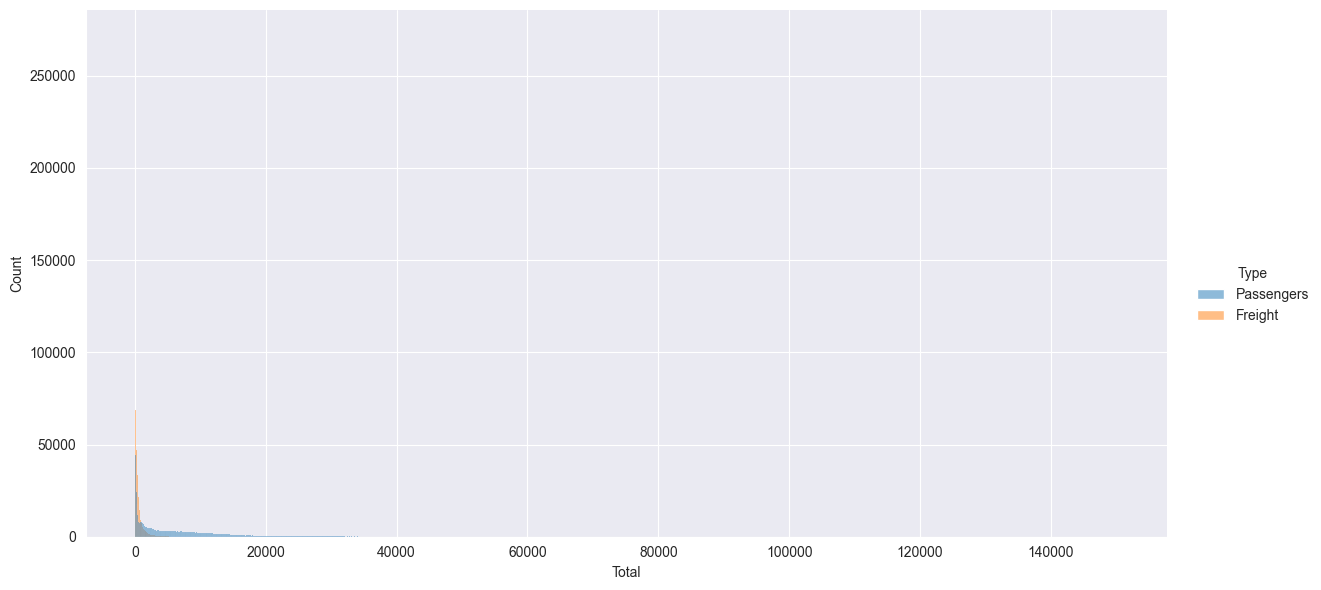

In [64]:
# Distribution of Passenger and Freight 
sns.displot(data=cleaned_df, x="Total", hue="Type",  height=6, aspect=2)

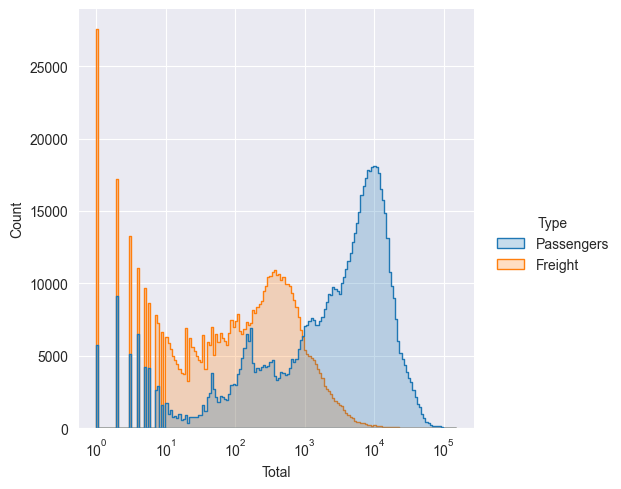

In [65]:
#Log-transform the counts for visualizing highly skewed data
sns.displot(data=cleaned_df, x="Total", hue="Type", log_scale=True, element="step")

##### Why Log-Transform Count Data?

When dealing with count data (like frequencies, populations, or occurrences), we often encounter highly skewed distributions where a few values are extremely large while most values are relatively small. Log-transforming such data serves several important purposes:

1. **Compresses wide ranges**: Log transformation reduces the influence of extremely large values, making patterns in both small and large values visible on the same scale.

2. **Normalizes skewed distributions**: It can make highly right-skewed data more symmetrical, helping reveal meaningful patterns that would otherwise be obscured.

3. **Improves visualization clarity**: In plots and graphs, log transformation prevents a few extreme values from compressing the rest of the data points into an unreadable cluster.

4. **Makes multiplicative relationships additive**: Changes that are proportional in the original data become linear in log space, making trends easier to interpret.


#### 2.6 Multivariate Analysis

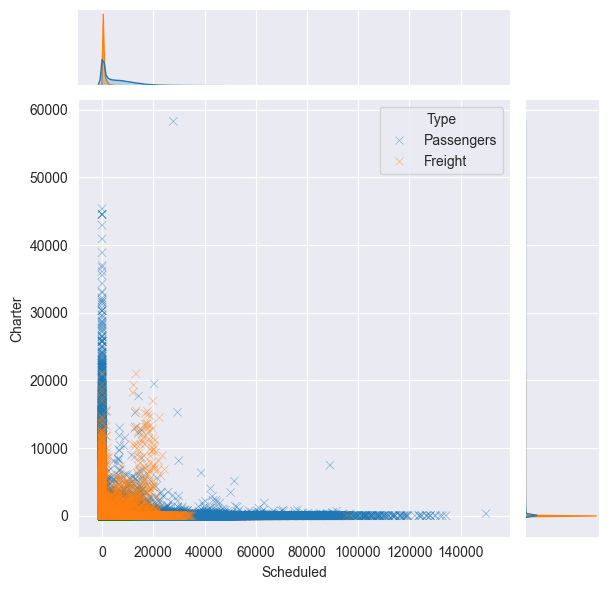

In [68]:
# Let us use a joinplot to further evaluate the relationship between the Scheduled and Charter flights
sns.jointplot(data=cleaned_df, x="Scheduled", y="Charter", hue="Type", alpha=.5, marker="x")

##### Benefits of Using a Joint Plot 

##### What This Plot Shows

The joint plot creates a multi-component visualization that includes:
- A scatter plot in the center showing "Scheduled" vs "Charter" values
- Marginal distributions (typically histograms or KDE plots) along the x and y axes
- Points colored by the "Type" categorical variable (using `hue`)
- Semi-transparent points (`alpha=.5`) with "x" markers

##### Benefits During Exploratory Data Analysis

1. **Relationship Examination**: Reveals correlation patterns between scheduled and charter values while simultaneously showing their individual distributions.

2. **Multivariate Patterns**: The `hue` parameter allows identification of how different categories in the "Type" variable might behave differently - perhaps certain types show distinct clustering or relationships.

3. **Data Density Insights**: The transparency setting helps identify where data points overlap, revealing dense regions that might otherwise be hidden.

4. **Outlier Detection**: Makes it easy to spot unusual combinations of values that deviate from the overall pattern.

5. **Distribution Context**: The marginal plots provide context about each variable's distribution without requiring separate visualizations.

6. **Hypothesis Generation**: These visual patterns can suggest relationships to investigate further with statistical testing.

This single plot efficiently combines multiple dimensions of information, making it valuable for quickly understanding complex relationships in your data before moving to more formal analyses.

## 3. Feature Engineering

Task: 
- Our task is to analyse the data over the years, for given airports. 
- We are also interested in analysing the type of flight operations for the given airports

Next Steps: 
- Until now, we have only concatenated the freight and passenger data --> Meaning there are multiple entries for same airport within the same year.
- Our task is to aggregate the data over the Years, with Unique Airport code and Types --> Meaning we create unique combinations of Year, AirportCiode and Type and aggregate the other columns 

In [75]:
# Group by Year, AirportCode, and Type, and apply aggregations
grouped_df = cleaned_df.groupby(['Year', 'AirportCode', 'Type']).agg(
    Airline=('Airline', 'nunique'),  # Gives us the unique count of airlines
    carriergroup=('carriergroup', lambda x: sorted(list(x.unique()))),  # Unique values of carriergroup
    Scheduled=('Scheduled', 'sum'),  # Sum of Scheduled flights
    Charter=('Charter', 'sum'),  # Sum of Charter flights
    Total=('Total', 'sum'),  # Sum of Total Pax/Freight
).reset_index()
grouped_df.sort_values(by=['Year', 'AirportCode', 'Type'], inplace=True)
grouped_df

,Year,AirportCode,Type,Airline,carriergroup,Scheduled,Charter,Total
0,1990,ABE,Passengers,2,[1],143,198,341
1,1990,ABQ,Passengers,2,"[0, 1]",0,941,941
2,1990,ACY,Passengers,9,"[0, 1]",367,27153,27520
3,1990,ADW,Passengers,2,[1],0,3964,3964
4,1990,AGS,Passengers,1,[1],39,0,39
...,...,...,...,...,...,...,...,...
12095,2024,YIP,Passengers,1,[0],0,5,5
12096,2024,YKM,Passengers,1,[1],0,8,8
12097,2024,YNG,Passengers,1,[0],0,1,1
12098,2024,YUM,Passengers,2,[1],0,2825,2825


Notice the column "carriergroup", it basically shows that an airport might only serve domestic carrier, or only international or both. Let us switch it from a list to a number

If [0] then: 0 (Domestic only)

If [1] then:1 (International)

If [0,1] then 2: (both Dom. and Int.)

In [76]:
# Define a function to map carriergroup values
def map_carriergroup(value):
    if value == [0]:
        return 'domestic'
    elif value == [1]:
        return 'international'
    elif value == [0, 1]:
        return 'both'
    else:
        return value  # Handle unexpected cases
# Apply the mapping function to the carriergroup column
grouped_df['Dom/Int'] = grouped_df['carriergroup'].apply(map_carriergroup)
grouped_df = grouped_df.drop('carriergroup', axis=1)  # dropped the temporary unique column
grouped_df.sort_values(by=['Year', 'AirportCode'])

,Year,AirportCode,Type,Airline,Scheduled,Charter,Total,Dom/Int
0,1990,ABE,Passengers,2,143,198,341,international
1,1990,ABQ,Passengers,2,0,941,941,both
2,1990,ACY,Passengers,9,367,27153,27520,both
3,1990,ADW,Passengers,2,0,3964,3964,international
4,1990,AGS,Passengers,1,39,0,39,international
...,...,...,...,...,...,...,...,...
12095,2024,YIP,Passengers,1,0,5,5,domestic
12096,2024,YKM,Passengers,1,0,8,8,international
12097,2024,YNG,Passengers,1,0,1,1,domestic
12098,2024,YUM,Passengers,2,0,2825,2825,international


Next we need to pivot the table such that for each airport, for each year, we get the values of all the variable as separate columns, especially for pax and freight.

In [82]:
# Pivot the DataFrame
pivot_df = grouped_df.pivot_table(
    index=['Year', 'AirportCode'],
    columns= ['Type'],
    values=['Airline', 'Scheduled', 'Charter', 'Total', 'Dom/Int'],
    aggfunc='sum'
).reset_index(drop=False)
# Rename the columns with Pax for Passengers and Cargo for Freight as a suffix

# Flatten the column names
pivot_df.columns = ['_'.join(col).strip() for col in pivot_df.columns.values]


# And fill the NaN values with 0
pivot_df = pivot_df.fillna(0)
pivot_df.head()

## Here the value 0 for Dom/Int_Freight or Passenger means that the airport does not have any freight or Passenger flights

,Year_,AirportCode_,Airline_Freight,Airline_Passengers,Charter_Freight,Charter_Passengers,Dom/Int_Freight,Dom/Int_Passengers,Scheduled_Freight,Scheduled_Passengers,Total_Freight,Total_Passengers
0,1990,ABE,0.00,2.00,0.00,198.00,0,international,0.00,143.00,0.00,341.00
1,1990,ABQ,0.00,2.00,0.00,941.00,0,both,0.00,0.00,0.00,941.00
2,1990,ACY,0.00,9.00,0.00,27153.00,0,both,0.00,367.00,0.00,27520.00
3,1990,ADW,0.00,2.00,0.00,3964.00,0,international,0.00,0.00,0.00,3964.00
4,1990,AGS,0.00,1.00,0.00,0.00,0,international,0.00,39.00,0.00,39.00


In [79]:
# save the file for Further Usecase
pivot_df.to_csv('airport_data.csv', index=False)

# **Clustering Use Case**

In this notebook we will walk through an example of a Clustering use case including the following steps:

1. **Import packages**
2. **Import dataset**
3. **Clustering**
    - 3.1. Data preparation
    - 3.2. Data visualization
    - 3.3. Feature engineering
    - 3.4. Modelling
    - 3.5. Make predictions
    - 3.6. Visualization of results


**What do we want to cluster ?**

## 1. Import packages

In [83]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")
pd.set_option('display.float_format', '{:.2f}'.format)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


## 2. Import dataset

In this jupyter notebook we are working with the dataset referring to USA airports. The dataset contains the yearly number of passengers and Kilos of transported freight for 1032 USA airports between 1990 and 2024. The dataset is stored as a CSV file and could be opened using Excel. However, for our in-depth analysis and the use of Machine Learing techniques, we load the dataset into this jupyter notebook as a pandas DataFrame. Therefore, we can use the `read_csv()` function of the pandas (`pd`) library. The passed argument `'./airport_data.csv'` defines the *file path of the excel file*.

In [103]:
# Read the CSV data by using read_csv() as a DataFrame and store it in a variable named 'airports'
df = pd.read_csv('airport_data.csv')

# Check the first few entries of the 'airports' dataframe by using head() function.
df.head()

,Year_,AirportCode_,Airline_Freight,Airline_Passengers,Charter_Freight,Charter_Passengers,Dom/Int_Freight,Dom/Int_Passengers,Scheduled_Freight,Scheduled_Passengers,Total_Freight,Total_Passengers
0,1990,ABE,0.00,2.00,0.00,198.00,0,international,0.00,143.00,0.00,341.00
1,1990,ABQ,0.00,2.00,0.00,941.00,0,both,0.00,0.00,0.00,941.00
2,1990,ACY,0.00,9.00,0.00,27153.00,0,both,0.00,367.00,0.00,27520.00
3,1990,ADW,0.00,2.00,0.00,3964.00,0,international,0.00,0.00,0.00,3964.00
4,1990,AGS,0.00,1.00,0.00,0.00,0,international,0.00,39.00,0.00,39.00


## 3. Feature Engineering

**ANS: We want to cluster different airports**

Let us rename some of the columns for brevity. And let us use pandas method .desrcribe() to summary statistics of numerical columns in a DataFrame, including count, mean, standard deviation, minimum, 25th percentile, median (50th percentile), 75th percentile, and maximum values.

In [104]:
# Rename the columns for better understanding
df = df.rename(
    columns={
        'Year_': 'Year', 
        'AirportCode_': 'AirportCode',
        "Airline_Freight": "No of airlines for Cargo",
        "Airline_Passengers": "No of airlines for Pax",
        "Charter_Freight": "Cargo flown by Charter",
        "Scheduled_Freight": "Cargo flown by Scheduled",
        "Total_Freight": "Total Cargo flown",
        "Charter_Passengers": "Pax flown by Charter",
        "Scheduled_Passengers": "Pax flown by Scheduled",
        "Total_Passengers": "Total Pax flown",
        "Dom/Int_Freight": "Dom/Int Cargo flown",
        "Dom/Int_Passengers": "Dom/Int Pax flown",
        }
    )

# Some fo the columns from above like Dom/Int Cargo flown, Dom/Int Pax flown are categorical variables. Change it to category dtype
df['Dom/Int Cargo flown'] = df['Dom/Int Cargo flown'].astype('category')
df['Dom/Int Pax flown'] = df['Dom/Int Pax flown'].astype('category')
# Summary statistics
df.head()

,Year,AirportCode,No of airlines for Cargo,No of airlines for Pax,Cargo flown by Charter,Pax flown by Charter,Dom/Int Cargo flown,Dom/Int Pax flown,Cargo flown by Scheduled,Pax flown by Scheduled,Total Cargo flown,Total Pax flown
0,1990,ABE,0.00,2.00,0.00,198.00,0,international,0.00,143.00,0.00,341.00
1,1990,ABQ,0.00,2.00,0.00,941.00,0,both,0.00,0.00,0.00,941.00
2,1990,ACY,0.00,9.00,0.00,27153.00,0,both,0.00,367.00,0.00,27520.00
3,1990,ADW,0.00,2.00,0.00,3964.00,0,international,0.00,0.00,0.00,3964.00
4,1990,AGS,0.00,1.00,0.00,0.00,0,international,0.00,39.00,0.00,39.00


In [92]:
df.describe()

,Year,No of airlines for Cargo,No of airlines for Pax,Total Cargo flown,Total Pax flown
count,7761.00,7761.00,7761.00,7761.00,7761.00
mean,2008.92,5.19,8.72,37255.35,670496.25
std,9.89,11.48,13.77,188377.60,2570281.52
min,1990.00,0.00,0.00,0.00,0.00
25%,2001.00,0.00,1.00,0.00,66.00
50%,2010.00,1.00,3.00,15.00,678.00
75%,2017.00,5.00,10.00,1318.00,53906.00
max,2024.00,111.00,112.00,2858616.00,34069637.00


For our current purposes, let us drop Chartered and Scheduled columns, and focus only on the totals. Why would this be okay?

In [105]:
# lets drop these columns ["Cargo flown by Charter", "Pax flown by Charter", "Cargo flown by Scheduled", "Pax flown by Scheduled"]

df = df.drop(columns=["Cargo flown by Charter", "Pax flown by Charter", "Cargo flown by Scheduled", "Pax flown by Scheduled"])
df.head()

,Year,AirportCode,No of airlines for Cargo,No of airlines for Pax,Dom/Int Cargo flown,Dom/Int Pax flown,Total Cargo flown,Total Pax flown
0,1990,ABE,0.00,2.00,0,international,0.00,341.00
1,1990,ABQ,0.00,2.00,0,both,0.00,941.00
2,1990,ACY,0.00,9.00,0,both,0.00,27520.00
3,1990,ADW,0.00,2.00,0,international,0.00,3964.00
4,1990,AGS,0.00,1.00,0,international,0.00,39.00


#### Understanding the data : Advanced visualization

/var/folders/dg/j13ccx9n15d_5l7j8nhkrhx40000gq/T/ipykernel_40767/3862437911.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=90)
/var/folders/dg/j13ccx9n15d_5l7j8nhkrhx40000gq/T/ipykernel_40767/3862437911.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=90)


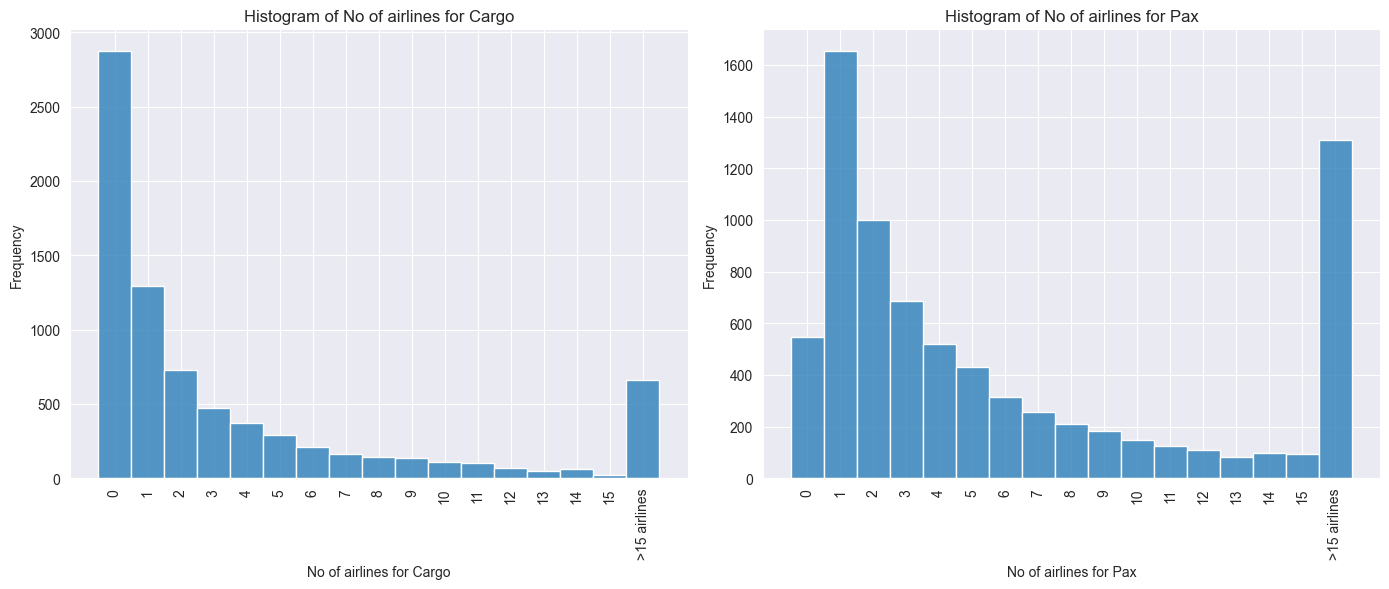

In [106]:
# List of numerical columns
columns_of_interest = [
    'No of airlines for Cargo',
    'No of airlines for Pax'
]

# Function to group values
def group_values(x):
    if x > 15:
        return '>15 airlines'
    else:
        return str(int(x))

# Apply the function to the columns of interest
for col in columns_of_interest:
    df[col + '_grouped'] = df[col].apply(group_values)

# Convert the grouped columns to categorical type
for col in columns_of_interest:
    df[col + '_grouped'] = pd.Categorical(df[col + '_grouped'], categories=[str(i) for i in range(16)] + ['>15 airlines'], ordered=True)

# Set up the figure and axes
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

# Plot histograms for each grouped column of interest
for i, col in enumerate(columns_of_interest):
    sns.histplot(df[col + '_grouped'], kde=False, ax=axes[i], discrete=True)
    axes[i].set_title(f'Histogram of {col}')
    axes[i].set_xlabel(col, rotation=0)
    axes[i].set_ylabel('Frequency')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=90)

# Remove the columns created above, since these are not needed anymore
df = df.drop([col + '_grouped' for col in columns_of_interest], axis=1)
# Adjust layout and display the plots
plt.tight_layout()
plt.show()

#### Understanding the data : Advanced visualization

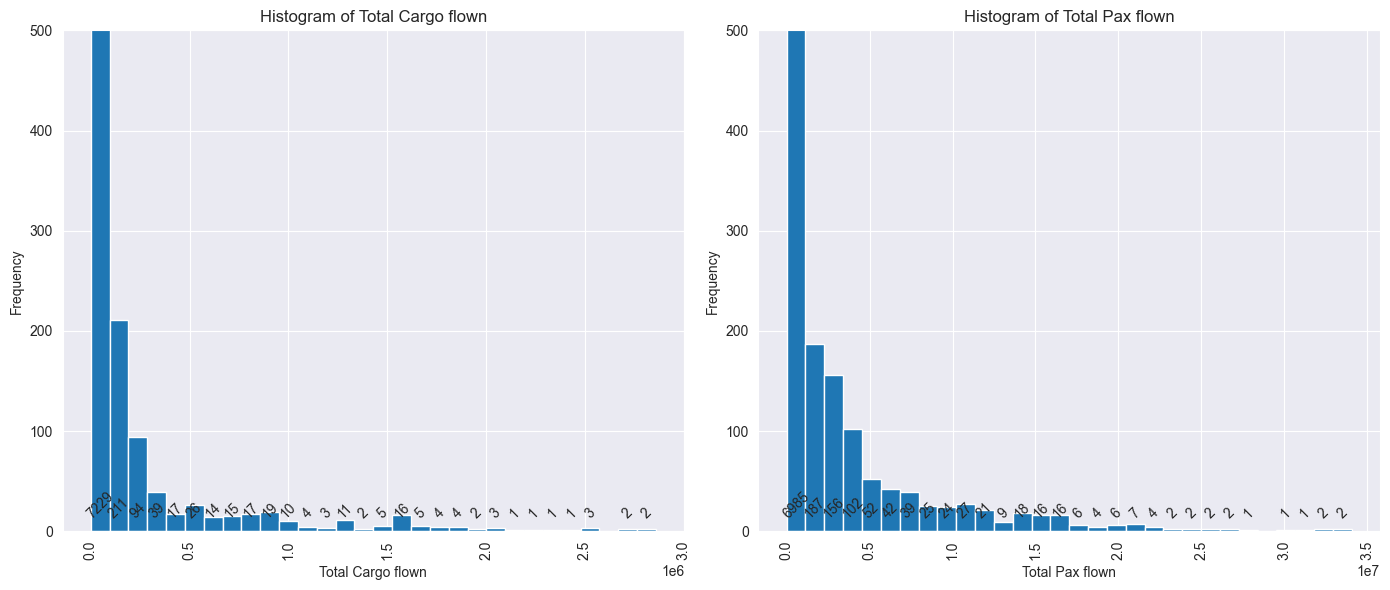

In [107]:
# Set up the figure and axes
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))
# List of numerical columns
columns_of_interest = [
"Total Cargo flown",
'Total Pax flown'
]
# Plot histograms for each column of interest
for i, col in enumerate(columns_of_interest):
    counts, bins, patches = axes[i].hist(df[col], bins=30)  # Adjust the number of bins as needed
    axes[i].set_title(f'Histogram of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].tick_params(axis='x', rotation=90)
    axes[i].set_ylim(0, 500)  # Set y-axis limits

    # Overlay the actual counts on each bar
    for count, bin in zip(counts, bins):
        if count > 0:  # Only label bars with counts
            axes[i].text(bin + (bins[1] - bins[0]) / 2, 10, int(count), ha='center', va='bottom', rotation=45)

# Adjust layout and display the plots
plt.tight_layout()
plt.show()

#### Understanding the data : Relation between Passenger and Freight

What kind of relationship do we expect between the no. of Pax handled and the amount of cargo handeled? We can visualize this using correlation matrix.

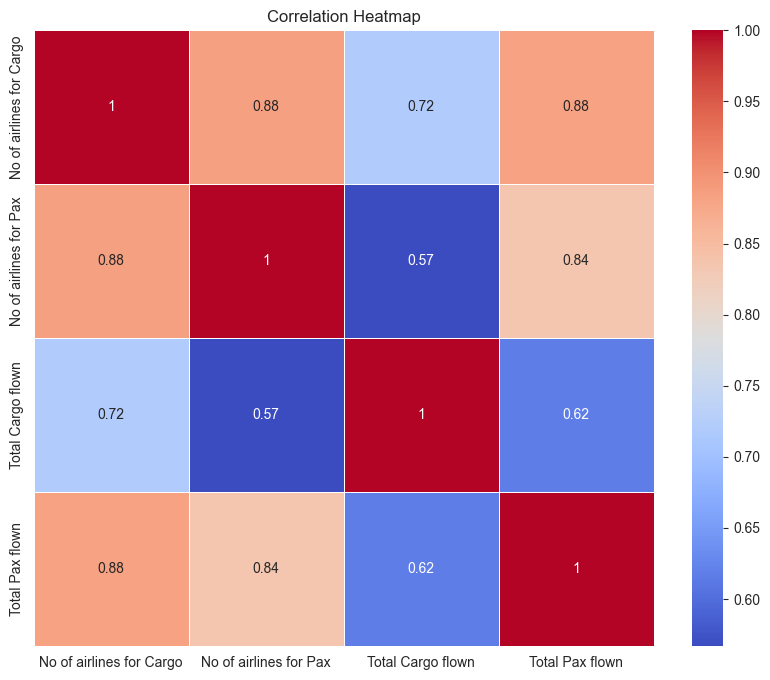

In [108]:
# List of numerical columns
numerical_columns = [
    'No of airlines for Cargo',
    'No of airlines for Pax',
    'Total Cargo flown',
    'Total Pax flown'
]

# Calculate the correlation matrix by using corr() function
correlation_matrix = df[numerical_columns].corr()

# Create a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

**Understanding the ABove Matrix**
- What do you understand by the colors and the numbers 
- This means that airports that handle more passengers also tend to handle more cargo, and vice versa.
- The correlation of 0.62 is not very high, but also not insignificant, suggesting that these two measures move very closely together.

This strong relationship makes intuitive sense as larger airports generally have both more passenger traffic and cargo handling capabilities.

Discuss further correlations observed, what do they mean, why might we be seeing these values?

#### Understanding Categorical data 

Next, let us look at our data again, you will notice, we have not explore the categorical columns, "Dom/Int Cargo flown" & "Dom/Int Pax flown". Let us look into that.
- "Dom/Int Cargo flown" --> explains if the airport servce domestic/internation/both/none Cargo operations during that year.
- "Dom/Int Pax flown" --> explains if the airport servce domestic/internation/both/none Passenger operations during that year.

In [91]:
df.head()

,Year,AirportCode,No of airlines for Cargo,No of airlines for Pax,Dom/Int Cargo flown,Dom/Int Pax flown,Total Cargo flown,Total Pax flown
0,1990,ABE,0.00,2.00,0,international,0.00,341.00
1,1990,ABQ,0.00,2.00,0,both,0.00,941.00
2,1990,ACY,0.00,9.00,0,both,0.00,27520.00
3,1990,ADW,0.00,2.00,0,international,0.00,3964.00
4,1990,AGS,0.00,1.00,0,international,0.00,39.00


In [109]:
# As a first step, we can see how often each unique value appears in the 'Dom/Int Cargo flown' column 
print(df['Dom/Int Cargo flown'].value_counts())

Dom/Int Cargo flown
0                2876
both             2497
international    1944
domestic          444
Name: count, dtype: int64


In [110]:
# 0 shows that there are some airports which are only Passenger airports --> Interested in checking ? 
print(df[(df['Dom/Int Cargo flown'] == '0')]['AirportCode'].unique())
# Check when did ABE started Cargo operations 
print('ABE Airprt has first Cargo in  : ', df[((df['AirportCode']== 'ABE') & (df['Dom/Int Cargo flown'] != '0')) ]['Year'].min())
#df[((df['AirportCode']== 'ABE') & (df['Dom/Int Cargo flown'] != '0') & (df['Year'] == 1995)) ]

['ABE' 'ABQ' 'ACY' 'ADW' 'AGS' 'AMA' 'BFI' 'BOI' 'BTR' 'CAE' 'CHA' 'CMH'
 'COS' 'CRP' 'DAB' 'DCA' 'DLH' 'DSM' 'EVV' 'FSD' 'GRR' 'GSO' 'GSP' 'JAX'
 'LAN' 'LBB' 'LGB' 'MAF' 'MOT' 'MSN' 'MSO' 'NGU' 'NIP' 'PNS' 'POB' 'PSM'
 'PSP' 'PVD' 'PWM' 'RIC' 'RST' 'SAV' 'SBA' 'SBN' 'SFB' 'SRQ' 'SUU' 'TEB'
 'TLH' 'YKM' 'ABI' 'BFM' 'BHM' 'BUR' 'CAK' 'CPR' 'GJT' 'IAG' 'ILM' 'ISP'
 'KOA' 'LIT' 'MBS' 'MDW' 'MHT' 'MRY' 'OMA' 'OPF' 'RFD' 'SPS' 'TYS' 'VRB'
 'ALB' 'BTV' 'CID' 'DAL' 'EGE' 'FAR' 'FWA' 'HOU' 'LEX' 'MDT' 'OGG' 'RNO'
 'SHV' 'ACT' 'FOE' 'GFK' 'GRK' 'GTF' 'HPN' 'ILG' 'ISO' 'LNK' 'ORF' 'PIE'
 'SMF' 'YNG' 'AEX' 'BED' 'EIL' 'FAT' 'FRG' 'JNU' 'MKC' 'ORH' 'PAE' 'TCM'
 'TRM' 'CRW' 'FCA' 'GRB' 'LIH' 'LSV' 'MTH' 'PTK' 'BDR' 'BMI' 'MVY' 'NTD'
 'PUB' 'STT' 'AFW' 'EDF' 'ERI' 'ICT' 'IFP' 'BKL' 'BLV' 'COU' 'INT' 'JAC'
 'MLB' 'YUM' 'APF' 'EYW' 'SNA' 'INL' 'N1C' 'ROC' 'CLL' 'FTW' 'AVL' 'LKE'
 'MPB' 'ACK' 'APA' 'BCT' 'EUG' 'FRD' 'ITH' 'ORL' 'SDM' 'TTN' 'BZN' 'FOK'
 'LBE' 'MKG' 'PDK' 'TUS' 'VNY' 'BJC' 'FPR' 'FXE' 'H

In [97]:
print(df['Dom/Int Pax flown'].value_counts())

# you can perform similar analysis as above for Passenger 

Dom/Int Pax flown
both             4278
international    1969
domestic          968
0                 546
Name: count, dtype: int64


#### Explore the relation between the Freight and Passenger data 

**Lets visualize the distribution of airports against Total passenger and Total Cargo flown . As a third dimension we also see how many of them are domestic/internation/both/none**

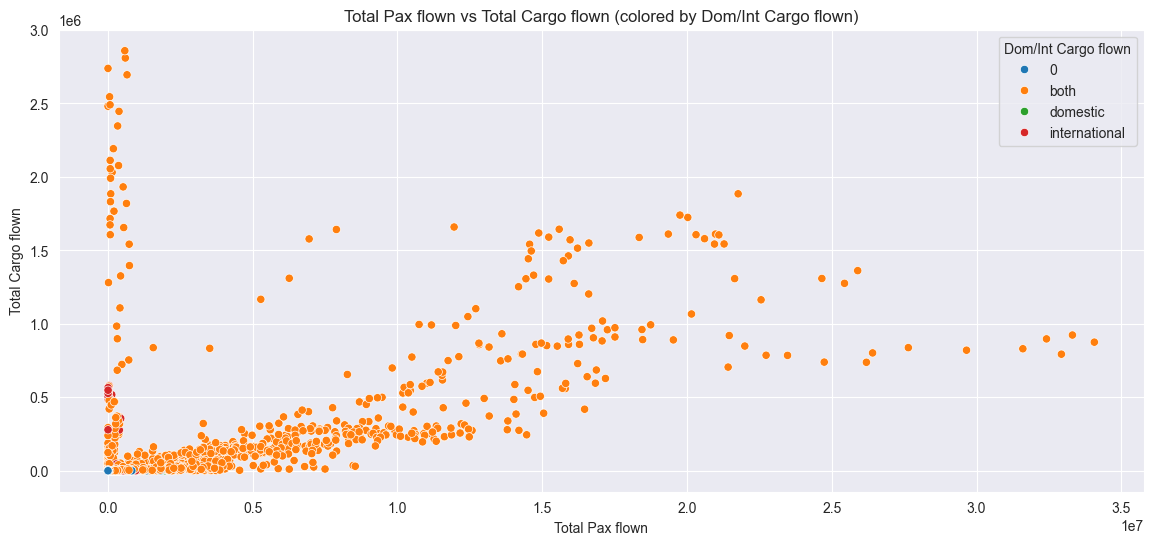

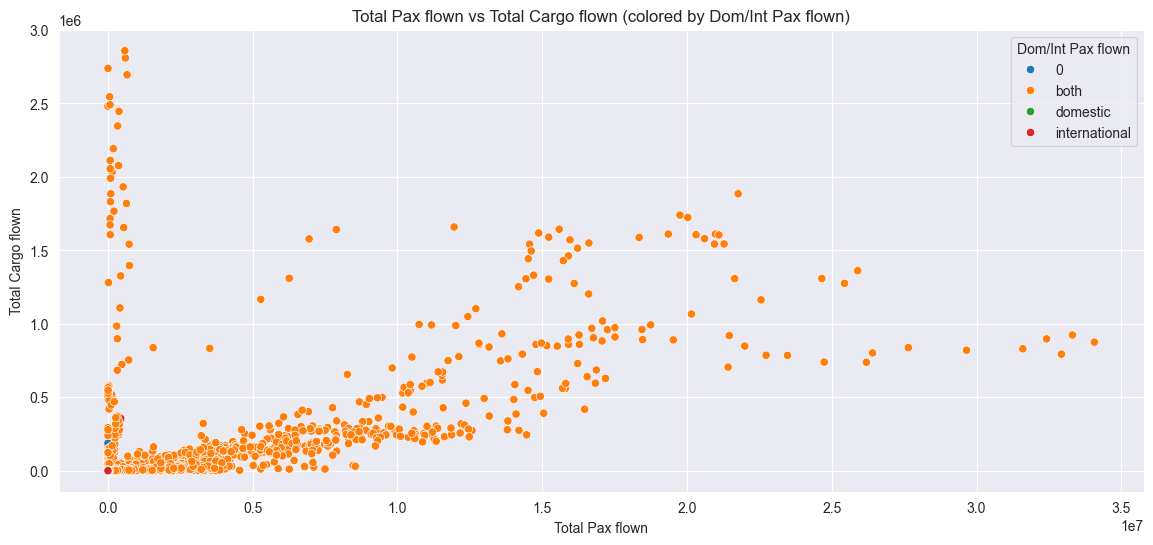

In [111]:
import seaborn as sns
import matplotlib.pyplot as plt

# Scatter plot for Total Pax flown vs Total Cargo flown, colored by Dom/Int Cargo flown
plt.figure(figsize=(14, 6))
sns.scatterplot(data=df, x='Total Pax flown', y='Total Cargo flown', hue='Dom/Int Cargo flown')
plt.title('Total Pax flown vs Total Cargo flown (colored by Dom/Int Cargo flown)')
plt.xlabel('Total Pax flown')
plt.ylabel('Total Cargo flown')
plt.show()

# Scatter plot for Total Pax flown vs Total Cargo flown, colored by Dom/Int Pax flown
plt.figure(figsize=(14, 6))
sns.scatterplot(data=df, x='Total Pax flown', y='Total Cargo flown', hue='Dom/Int Pax flown')
plt.title('Total Pax flown vs Total Cargo flown (colored by Dom/Int Pax flown)')
plt.xlabel('Total Pax flown')
plt.ylabel('Total Cargo flown')
plt.show()

Observation: 
- A strong correlation between the freight and passenger data is visible
- Most of the datapoints are both Internation & Domestic
- No clear groups are visible

Hence, lets try to aggregate the data more and remove the unwanted columns 


In [112]:
# Remove the columns that are not required ['Dom/Int Cargo flown', 'Dom/Int Pax flown', 'No of airlines for Cargo', 'No of airlines for Pax']
df = df.drop(columns=['Dom/Int Cargo flown', 'Dom/Int Pax flown', 'No of airlines for Cargo', 'No of airlines for Pax'], axis=1)

df

,Year,AirportCode,Total Cargo flown,Total Pax flown
0,1990,ABE,0.00,341.00
1,1990,ABQ,0.00,941.00
2,1990,ACY,0.00,27520.00
3,1990,ADW,0.00,3964.00
4,1990,AGS,0.00,39.00
...,...,...,...,...
7756,2024,YIP,174.00,5.00
7757,2024,YKM,0.00,8.00
7758,2024,YNG,0.00,1.00
7759,2024,YUM,0.00,2825.00


Let's aggregate the data by airport code.

Note, we have used the median of the No of passengers and Cargo weight handled, to arrive at singular aggregated values of these variables for each airport. You can try using mean, sum or simply selecting the value of 2024 alone to run the clustering algorithm, if you would like to try your hand at it.

In [113]:
# Aggregate data by airport
aggregated_df = df.groupby('AirportCode').agg({
    'Total Cargo flown': 'median',
    'Total Pax flown': 'median'
}).reset_index()
aggregated_df.head()


,AirportCode,Total Cargo flown,Total Pax flown
0,1FL,53.50,0.00
1,ABE,0.00,458.00
2,ABI,0.00,369.00
3,ABQ,0.00,1140.00
4,ACK,0.00,11.00


Let us do another quick describe of the numerical columns, using the .describe() method from pandas library.

In [114]:
# statistical summary of the aggregated data
aggregated_df.describe()

,Total Cargo flown,Total Pax flown
count,321.00,321.00
mean,25117.58,452114.37
std,152766.56,1980776.43
min,0.00,0.00
25%,0.00,16.00
50%,0.00,173.00
75%,139.50,3517.00
max,1831176.00,18444274.00


#### Scalerize the Data

Note, the difference in the maximum values of no of passengers and cargo weight handled. There is a difference in the range of the values of both these features. Many machine learning algorithms, especially those that rely on distance calculations like the one we will use today: k-means clustering are sensitive to the scale of input features.

Without standardization, the no of passengers weight feature would dominate the analysis simply because its values are much larger, not because it's more important. 

We use StandardScaler() to solve this by:
 - Subtracting the mean (centering the data)
 - Dividing by the standard deviation (scaling the data)
This transforms all features to have a mean of 0 and a standard deviation of 1, putting them on the same scale and ensuring each feature contributes proportionally to the analysis.

In [115]:
# Standardize the data using StandardScaler()
scaler = StandardScaler()
scaled_data = scaler.fit_transform(aggregated_df[['Total Pax flown', 'Total Cargo flown']])

# Convert scaled data back to DataFrame
scaled_df = pd.DataFrame(scaled_data, columns=['Total Pax flown Scaled', 'Total Cargo flown Scaled'])
scaled_df.head()


,Total Pax flown Scaled,Total Cargo flown Scaled
0,-0.23,-0.16
1,-0.23,-0.16
2,-0.23,-0.16
3,-0.23,-0.16
4,-0.23,-0.16


/var/folders/dg/j13ccx9n15d_5l7j8nhkrhx40000gq/T/ipykernel_40767/2061674452.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([aggregated_df['Total Pax flown'], aggregated_df['Total Cargo flown']],
/var/folders/dg/j13ccx9n15d_5l7j8nhkrhx40000gq/T/ipykernel_40767/2061674452.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([scaled_df['Total Pax flown Scaled'], scaled_df['Total Cargo flown Scaled']],


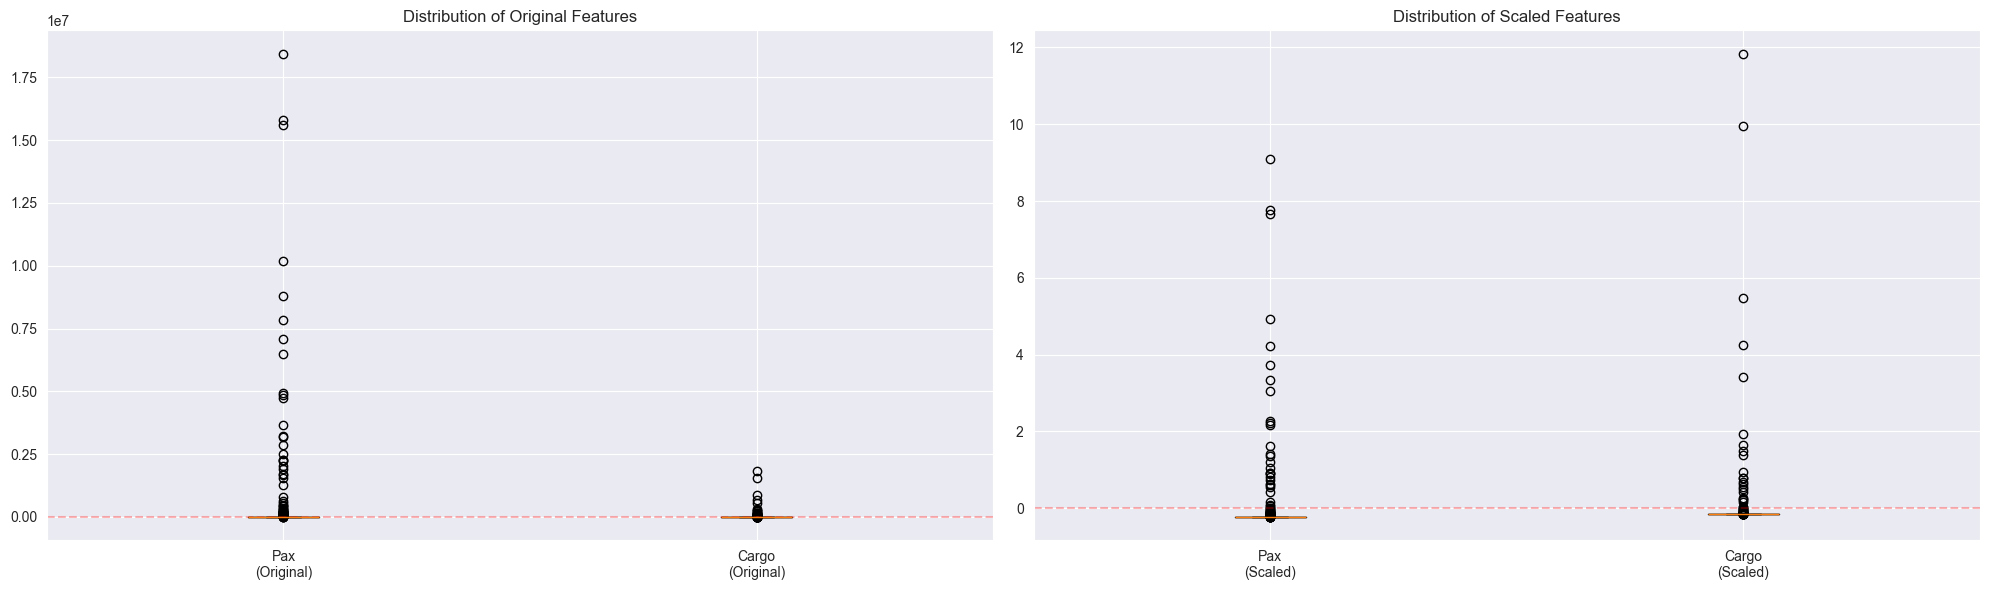

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

# Box plot for original features
axes[0].boxplot([aggregated_df['Total Pax flown'], aggregated_df['Total Cargo flown']], 
                labels=['Pax\n(Original)', 'Cargo\n(Original)'])
axes[0].set_title('Distribution of Original Features')
axes[0].axhline(y=0, color='r', linestyle='--', alpha=0.3)

# Box plot for scaled features
axes[1].boxplot([scaled_df['Total Pax flown Scaled'], scaled_df['Total Cargo flown Scaled']], 
                labels=['Pax\n(Scaled)', 'Cargo\n(Scaled)'])
axes[1].set_title('Distribution of Scaled Features')
axes[1].axhline(y=0, color='r', linestyle='--', alpha=0.3)

# Adjust layout and show the plots
plt.tight_layout()
plt.show()

## 4. Kmeans

#### Finding out how many clusters we need to form

When doing cluster analysis (like K-means clustering), we need to tell the algorithm how many clusters (k) to create. The elbow method helps us make this decision by measuring how well the clustering performs with different numbers of clusters. Note that clustering still remains unsupervised because specifying the number of clusters (k) is just a parameter of how to group the data - the algorithm still discovers the patterns and group assignments on its own without any pre-labeled examples to learn from.

Think of it like this: As we increase the number of clusters, the data points in each cluster become more similar to each other (reducing what we call "inertia" or within-cluster sum of squares). However, at some point, adding more clusters gives diminishing returns - like bending your arm at the elbow.

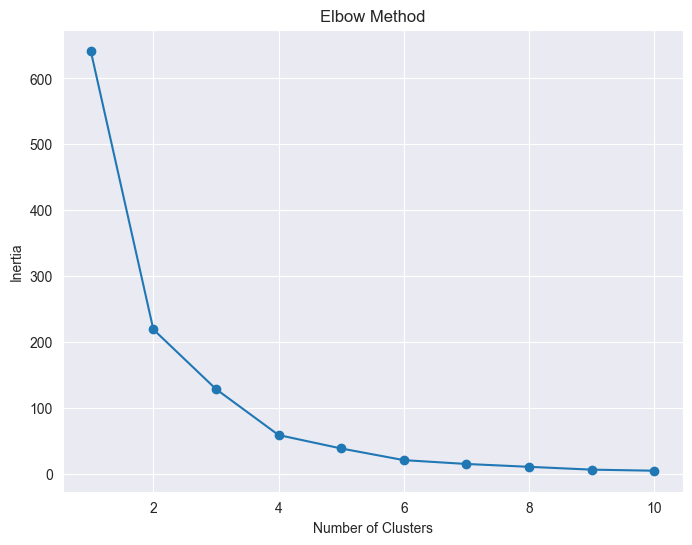

In [119]:
# Determine the optimal number of clusters using the Elbow Method
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_df)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(8, 6))
plt.plot(range(1, 11), inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()


On the graph above:
- The y-axis shows the inertia (how spread out the clusters are internally)
- The x-axis shows the number of clusters
- The line forms an "elbow" shape
- The optimal number of clusters is typically at this "elbow" point, where adding more clusters doesn't significantly improve the clustering quality

This point represents the best trade-off between having enough clusters to explain the data well, but not so many that we're over-complicating our model.

#### Kmeans clustering

Now, let us run with the chosen number of clusters, to actually run our algorithm.

In [121]:
# Apply KMeans clustering
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

aggregated_df['Cluster'] = kmeans.fit_predict(scaled_df)

The algorithm can randomly allocate either of the clusters aas 0,1,2. This does not necessarily mean that cluster 0 refers to the smallest aiports, or cluster 2 refers to the smallest airports. 

Hence, we calculate the median value of no of passengers for each cluster and use it to assign, automaticalls which number is referring to the larger airport and which to the smaller. 

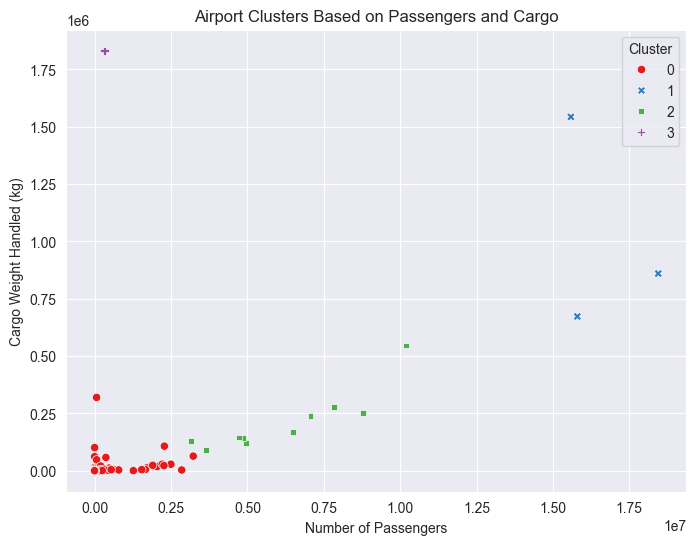

In [122]:
# Visualize the clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Total Pax flown', 
                y='Total Cargo flown', 
                hue='Cluster', 
                data=aggregated_df,
                style='Cluster', 
                palette='Set1')
plt.title('Airport Clusters Based on Passengers and Cargo')
plt.xlabel('Number of Passengers')
plt.ylabel('Cargo Weight Handled (kg)')
plt.show()


In [123]:
# Get median values for each cluster
median_by_cluster = aggregated_df.groupby('Cluster')['Total Pax flown'].median().sort_values(ascending=False)

# lets look how the cluster values are distributed
median_by_cluster.index

Index([1, 2, 3, 0], dtype='int32', name='Cluster')

In [124]:
# Create mapping dictionary based on sorted median values
cluster_mapping = {
    median_by_cluster.index[0]: 'High Passenger, high Cargo',
    median_by_cluster.index[1]: 'Medium Passenger, low Cargo',
    median_by_cluster.index[2]: 'Low Passenger, high Cargo',
    median_by_cluster.index[3]: 'Low Passenger, Low Cargo'
}

# Replace values in the Cluster column using the mapping
aggregated_df['Cluster'] = aggregated_df['Cluster'].replace(cluster_mapping)

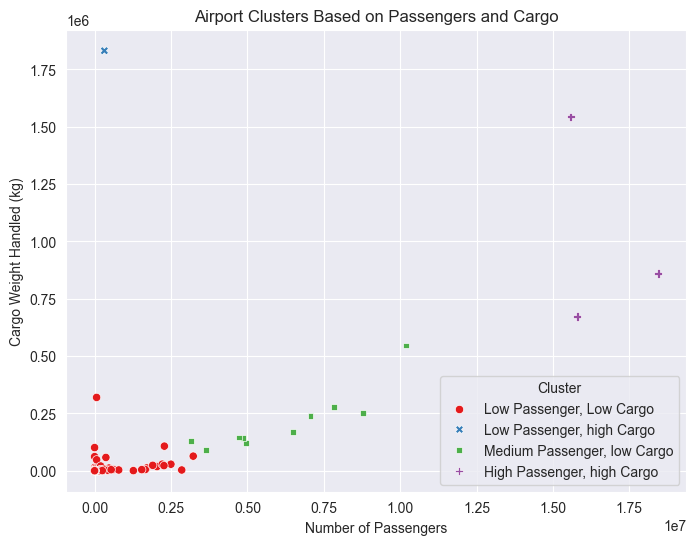

In [125]:
# Visualize the clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Total Pax flown', 
                y='Total Cargo flown', 
                hue='Cluster', 
                data=aggregated_df,
                style='Cluster', 
                palette='Set1')
plt.title('Airport Clusters Based on Passengers and Cargo')
plt.xlabel('Number of Passengers')
plt.ylabel('Cargo Weight Handled (kg)')
plt.show()


# **Advanced Clustering**

In [126]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")
pd.set_option('display.float_format', '{:.2f}'.format)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [127]:
# Read the CSV data by using read_csv() as a DataFrame and store it in a variable named 'airports'
airports = pd.read_csv('airport_data.csv')
# from earlier EDA, we know there are NaN values in the columns 'TotalPax' and 'TotalFreight'

# Rename the columns for better understanding
airports = airports.rename(
    columns={
        'TotalPax': 'No of passengers', 
        'TotalFreight': 'Cargo weight handled',
        'AirportCode': 'Airport'
        }
    )

# Check the first few entries of the 'airports' dataframe by using head() function.
airports.head()

,Year_,AirportCode_,Airline_Freight,Airline_Passengers,Charter_Freight,Charter_Passengers,Dom/Int_Freight,Dom/Int_Passengers,Scheduled_Freight,Scheduled_Passengers,Total_Freight,Total_Passengers
0,1990,ABE,0.00,2.00,0.00,198.00,0,international,0.00,143.00,0.00,341.00
1,1990,ABQ,0.00,2.00,0.00,941.00,0,both,0.00,0.00,0.00,941.00
2,1990,ACY,0.00,9.00,0.00,27153.00,0,both,0.00,367.00,0.00,27520.00
3,1990,ADW,0.00,2.00,0.00,3964.00,0,international,0.00,0.00,0.00,3964.00
4,1990,AGS,0.00,1.00,0.00,0.00,0,international,0.00,39.00,0.00,39.00


As in the previous clustering exercise, we remove all unwanted columns.

In [128]:
airports = airports[['Year_', 'AirportCode_', 'Total_Passengers', 'Total_Freight']]
airports = airports.rename(columns={'Year_': 'Year', 'AirportCode_': 'Airport', 'Total_Passengers': 'No of passengers', 'Total_Freight': 'Cargo weight handled'})
airports.head()

,Year,Airport,No of passengers,Cargo weight handled
0,1990,ABE,341.00,0.00
1,1990,ABQ,941.00,0.00
2,1990,ACY,27520.00,0.00
3,1990,ADW,3964.00,0.00
4,1990,AGS,39.00,0.00


There are data from 1990 to 2024. That is 35 years of data. But is there 35 years of data for each airport?

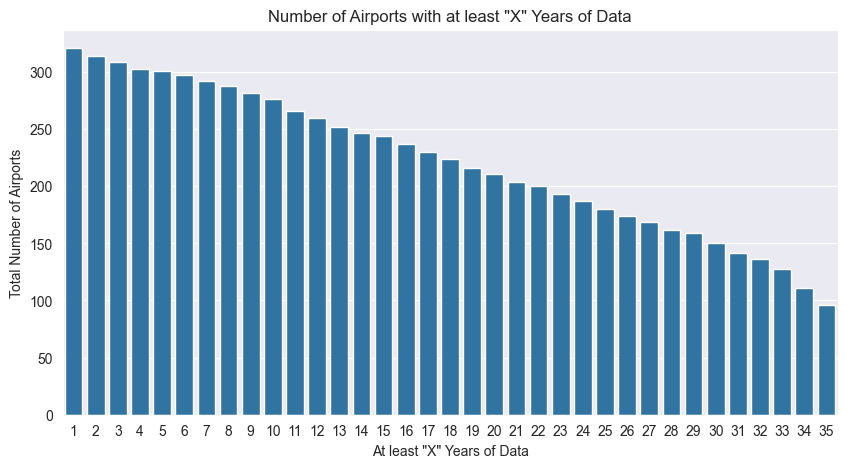

In [129]:
# Find out how many years of data is available for each airport, by counting the unique years for each airport
years_of_data = airports.groupby('Airport')['Year'].nunique().reset_index()
# Rename the columns
years_of_data.columns = ['Airport', 'Years of Data']
# Count how many airports have data for each number of years
years_of_data_counts = years_of_data['Years of Data'].value_counts().reset_index()
# Rename the columns
years_of_data_counts.columns = ['Years of Data', 'Counts of Airports']
# Sort the values by 'Years of Data' in descending order
years_of_data_counts = years_of_data_counts.sort_values(by='Years of Data', ascending=False).reset_index(drop=True)

# Add a cumulative sum column, to find out how many airports have data for at least a certain number of years
years_of_data_counts['Total Airports'] = years_of_data_counts['Counts of Airports'].cumsum()

# Add a label for the total airports, by flipping the cumulative sum column from above and resetting the index
years_of_data_counts['Label for Total Airports'] = years_of_data_counts['Total Airports'][::-1].reset_index(drop=True)

# Create a line plot with markers
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=years_of_data_counts, x='Years of Data', y='Total Airports')


    
# Set titles and labels
plt.title('Number of Airports with at least "X" Years of Data')
plt.xlabel('At least "X" Years of Data')
plt.ylabel('Total Number of Airports')

# Show the plot
plt.show()

There are 96 airports for which data is available for 35 years. Let us select all airports for which data is available for all years from 1900.

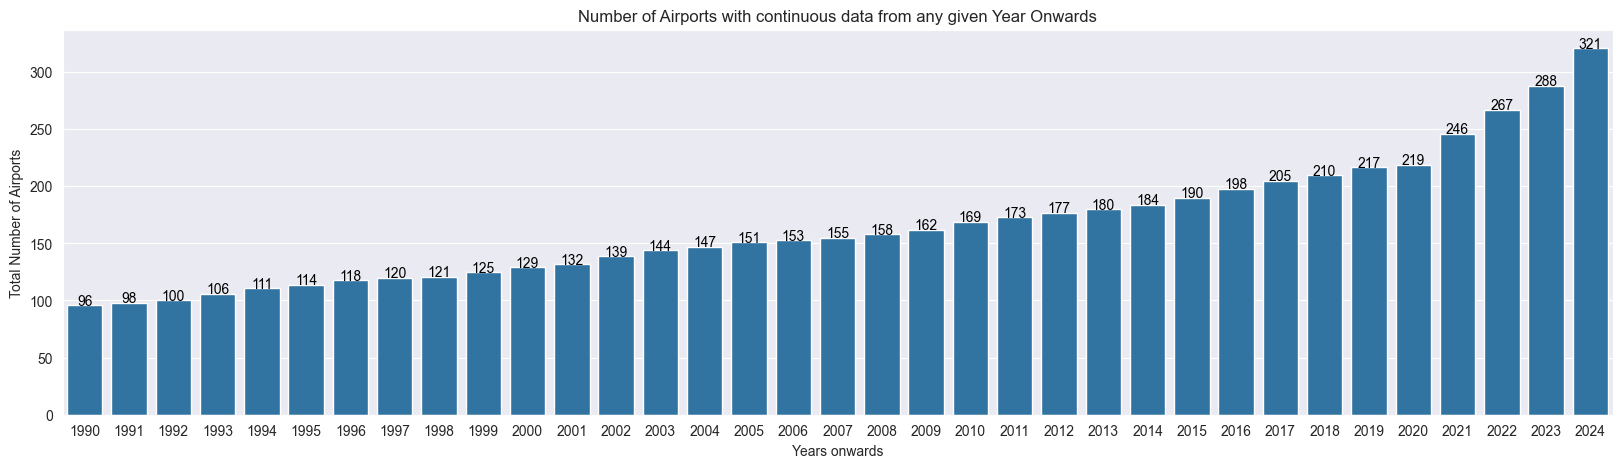

In [130]:
# Let us write a function that takes the input a dataframe, a value of the column Year, 
# and then returns how many airports from the dataframe have data from that year onwards until 2024.

def airports_with_data_from_year(df, year: int) -> int:
    
    # Assert that df is a pandas DataFrame
    assert isinstance(df, pd.DataFrame), "First input to the function should be a pandas DataFrame"

    # Assert that the provided value for year is an integer
    assert isinstance(year, int), "The provided value should be an integer"
    # Assert that the required columns are in the DataFrame
    required_columns = ['Airport', 'Year']
    assert all(column in df.columns for column in required_columns), f"The input dataFrame must contain the columns: {required_columns}"

    # Get the minimum and maximum values of the column
    try: 
        min_value = df["Year"].min()
    except:
        min_value = df["Year"].astype(int).min()
    try:
        max_value = df["Year"].max()
    except:
        max_value = df["Year"].astype(int).max()
    
    # Assert that the value is between the minimum and maximum of the column
    assert min_value <= year <= max_value, f"The second input should be between {min_value} and {max_value}"
    
    # Filter the dataframe for data from the given year and after that.
    filtered_df = df[df['Year'] >= year]
    # This only gives us airports that have data from the given year onwards.
    # Next we need to find out how many airports have data for each year from the given year onwards.
    years_of_data = filtered_df.groupby('Airport')['Year'].nunique().reset_index()
    years_of_data.columns = ['Airport', 'Years of Data']
    
    # Select airports with data for all years from 2000 to 2024
    required_years = 2024 - year + 1
    airports_with_full_data = years_of_data[years_of_data['Years of Data'] == required_years]['Airport']

    return len(airports_with_full_data)

# Initialize an empty DataFrame with columns 'Year' and 'Counts of Airports'
airports_data_year_onwards = pd.DataFrame(columns=['Year', 'Counts of Airports'])

for year in airports['Year'].unique():
    counts = airports_with_data_from_year(airports, int(year))
    temp_df = pd.DataFrame({'Counts of Airports': [counts], 'Year': [year]})

    # Append the counts and year to the results DataFrame
    airports_data_year_onwards = pd.concat([airports_data_year_onwards, temp_df], ignore_index=True)

airports_data_year_onwards = airports_data_year_onwards.sort_values(by='Year').reset_index(drop=True)
   
# Create a line plot with markers
plt.figure(figsize=(20, 5))
ax = sns.barplot(data=airports_data_year_onwards, x='Year', y='Counts of Airports')

# Add labels on each bar
for index, row in airports_data_year_onwards.iloc[::-1].iterrows():
    ax.text(row.name, row['Counts of Airports'], round(row['Counts of Airports'], 2), color='black', ha="center", rotation = 0)

# Set titles and labels
plt.title('Number of Airports with continuous data from any given Year Onwards')
plt.xlabel('Years onwards')
plt.ylabel('Total Number of Airports')

# Show the plot
plt.show()

In [131]:
# Filter data from the year 2000 and after
year = 2005
airports_filtered = airports[airports['Year'] >= year]

# Find out how many years of data is available for each airport
years_of_data = airports_filtered.groupby('Airport')['Year'].nunique().reset_index()
years_of_data.columns = ['Airport', 'Years of Data']

# Select airports with data for all years from 2000 to 2024
required_years = 2024 - year + 1
airports_with_full_data = years_of_data[years_of_data['Years of Data'] == required_years]['Airport']
print("There are", len(airports_with_full_data), "airports with data available for all years from 2000 to 2024.")

# Filter the original dataframe to include only these airports
airports_full_data = airports_filtered[airports_filtered['Airport'].isin(airports_with_full_data)].reset_index(drop=True)
airports_full_data.head()

There are 151 airports with data available for all years from 2000 to 2024.


,Year,Airport,No of passengers,Cargo weight handled
0,2005,ACY,766.00,95.00
1,2005,ADS,0.00,72.00
2,2005,ADW,2371.00,0.00
3,2005,AEX,783.00,163.00
4,2005,AFW,0.00,97.00


Note that we want to cluster the airports, but clustering algorithms expect each observation (in this case, each airport) to be represented as a single row in the input data. This means all the time series data for each airport must be "unrolled" into a single row.
We can do this by flattening the above data frame to bring all data into a single row per airport.

In [132]:
# Reshape the data so that each airport is a row, and each year's features are columns
reshaped_data = airports_full_data.pivot(index='Airport', columns='Year', values=['No of passengers', 'Cargo weight handled'])

# Flatten the MultiIndex columns
reshaped_data.columns = [f'{feature}-{year}' for feature, year in reshaped_data.columns]

# Reset the index
reshaped_data = reshaped_data.reset_index(drop=False)

reshaped_data.head()

,Airport,No of passengers-2005,No of passengers-2006,No of passengers-2007,No of passengers-2008,No of passengers-2009,No of passengers-2010,No of passengers-2011,No of passengers-2012,No of passengers-2013,...,Cargo weight handled-2015,Cargo weight handled-2016,Cargo weight handled-2017,Cargo weight handled-2018,Cargo weight handled-2019,Cargo weight handled-2020,Cargo weight handled-2021,Cargo weight handled-2022,Cargo weight handled-2023,Cargo weight handled-2024
0,ACY,766.00,1454.00,1565.00,1491.00,8441.00,11767.00,7093.00,3222.00,6072.00,...,0.00,7.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,ADS,0.00,0.00,0.00,2.00,0.00,0.00,0.00,0.00,0.00,...,9.00,0.00,0.00,0.00,3.00,5.00,0.00,0.00,0.00,0.00
2,ADW,2371.00,1442.00,935.00,3020.00,3737.00,901.00,670.00,517.00,842.00,...,0.00,0.00,0.00,0.00,0.00,10.00,0.00,0.00,0.00,0.00
3,AEX,783.00,1080.00,835.00,1289.00,1918.00,11439.00,12197.00,27191.00,26506.00,...,0.00,1.00,29.00,2.00,20.00,0.00,0.00,27.00,0.00,0.00
4,AFW,0.00,54.00,578.00,52.00,164.00,0.00,55.00,1400.00,555.00,...,42.00,63.00,8.00,105.00,56.00,58.00,87.00,8.00,66.00,0.00


Next step is to normalize the data. Refer to the earlier part of the notebook to understand why we standardize datasets.

In [133]:
# Drop the 'Airport' column for normalization
data_to_normalize = reshaped_data.drop(columns=['Airport'])

# Normalize the data
scaler = StandardScaler()
normalized_data = scaler.fit_transform(data_to_normalize)

Next, we run the kmeans clustering algorithm using the same number of cluster as previously chosen, k=3/4. We can also do the elbow method here to evaluate the best cluster number.

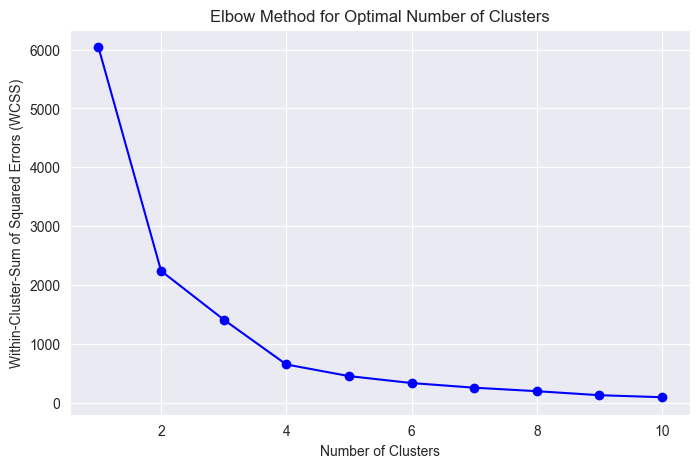

In [134]:
# Initialize a list to store Within-Cluster-Sum of Squared Errors (WCSS)
wcss = []

# Define the range of clusters to test
cluster_range = range(1, 11)  # Test from 1 to 10 clusters

# Calculate WCSS for each number of clusters
for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)  # Use n_init to avoid warnings
    kmeans.fit(normalized_data)
    wcss.append(kmeans.inertia_)  # inertia_ gives the WCSS

# Plot the Elbow Method graph
plt.figure(figsize=(8, 5))
plt.plot(cluster_range, wcss, marker='o', linestyle='-', color='b')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Within-Cluster-Sum of Squared Errors (WCSS)')
plt.grid(True)
plt.show()


In [135]:
# Fit the KMeans model
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)  # Choose the number of clusters
clusters = kmeans.fit_predict(normalized_data)

# Add cluster labels to the reshaped data
reshaped_data['Cluster'] = clusters

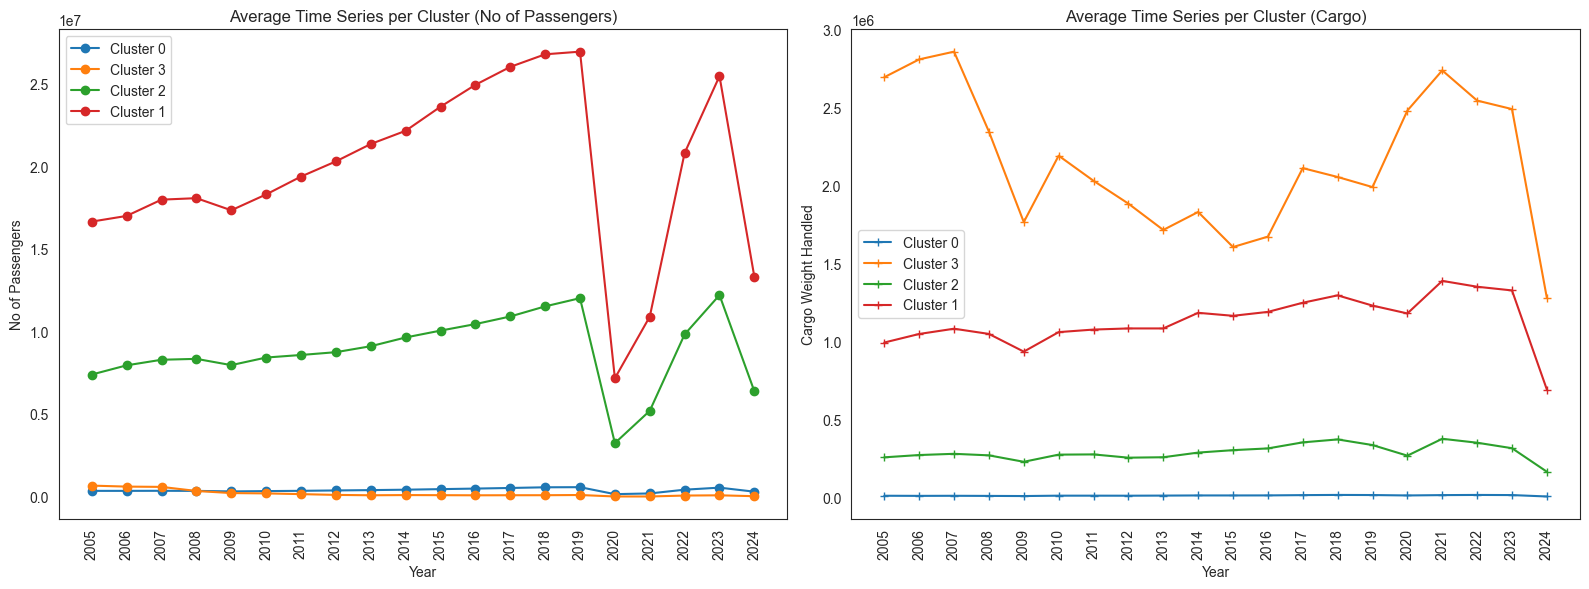

In [136]:
#Set the plot background to white
sns.set_style("white")

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for cluster in reshaped_data['Cluster'].unique():
    cluster_data = reshaped_data[reshaped_data['Cluster'] == cluster].drop(columns=['Airport', 'Cluster'])
    cluster_mean = cluster_data.mean(axis=0)
    
    # Plot for indices that start with "No of"
    no_of_indices = [idx for idx in cluster_mean.index if idx.startswith("No of")]
    axes[0].plot(no_of_indices, cluster_mean[no_of_indices].values, marker='o', label=f'Cluster {cluster}')
    
    # Plot for indices that start with "Cargo"
    cargo_indices = [idx for idx in cluster_mean.index if idx.startswith("Cargo")]
    axes[1].plot(cargo_indices, cluster_mean[cargo_indices].values, marker='+', label=f'Cluster {cluster}')

# Set titles and labels for the first subplot
axes[0].set_title('Average Time Series per Cluster (No of Passengers)')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('No of Passengers')
axes[0].legend()

# Set titles and labels for the second subplot
axes[1].set_title('Average Time Series per Cluster (Cargo)')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Cargo Weight Handled')
axes[1].legend()

# Modify x-tick labels to show only the part after "-"
for ax in axes:
    xtick_labels = [label.get_text().split('-')[-1] for label in ax.get_xticklabels()]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ax.set_xticklabels(xtick_labels, rotation=90)
        
        
# Adjust layout and show the plots
plt.tight_layout()
plt.show()

What does the plot of 3 different cluster tell us? What kind of airports are there depending upon their growth?

In the next steps, you can further tune the Model.
Feel free to experiment with:
1. Different numbers of clusters (n_clusters).
2. Different clustering algorithms (e.g., hierarchical clustering, DBSCAN).
3. Feature engineering (e.g., adding lagged features or rolling statistics).